<p style="font-size:300%; background-color:#ffe6f0; color:#0044cc; text-align:center; line-height:80px; margin:0; padding:0;"> <b>Filtros y Morfología Matemática</b> </p>

<p style="font-size:240%; background-color:#ffe6f0; color:#cc0000; text-align:center; line-height:60px; margin:0; padding:0;">
  <b>Inteligencia Artificial & Mini Robots</b>
</p>

<p style="font-size:200%; text-align:center; line-height:40px; margin:0;">
  <br><b>Prof. Flavio Prieto</b>
</p>

<p style="font-size:160%; text-align:center; line-height:25px; margin:0;">
  email: <a href="mailto:faprietoo@unal.edu.co">faprietoo@unal.edu.co</a>
</p>

<p style="font-size:180%; text-align:center; line-height:30px; margin:0;">
  <br><b>DEPARTAMENTO DE INGENIERÍA MECÁNICA Y MECATRÓNICA</b>
</p>

<p style="font-size:180%; text-align:center; line-height:30px; margin:0;">
  Facultad de Ingeniería
</p>

<p style="font-size:160%; text-align:center; line-height:30px; margin:0;">
  Universidad Nacional de Colombia – Sede Bogotá
</p>

<div style="text-align:center; margin-top:20px; margin-bottom:10px;">
  <img src="Fig/Escudo_UN.png" alt="Escudo UNAL" width="90" style="border:none;">
</div>


# **Filtrado de Imágenes en el Dominio Espacial**

## Convolución

In [1]:
import numpy as np

f = np.array([
    [2, 3, 0, 1, 2],
    [4, 6, 2, 1, 0],
    [3, 1, 5, 7, 2],
    [0, 2, 3, 6, 1],
    [1, 1, 0, 2, 4]
])

w = np.array([
    [0, 1, 0],
    [1, -4, 1],
    [0, 1, 0]
])

x_idx, y_idx = 2, 2  # índice Python para (3,3)

terms = []
for s in range(-1, 2):
    for t in range(-1, 2):
        w_val = w[s+1, t+1]
        f_val = f[x_idx - s, y_idx - t]
        prod = w_val * f_val
        terms.append((s, t, w_val, f_val, prod))

print("Detalle paso a paso de g(3,3):\n")
for s, t, wv, fv, p in terms:
    x_coord = 3 - s
    y_coord = 3 - t
    print(f"w({s:+d},{t:+d}) * f({x_coord},{y_coord}) = {wv:2d} * {fv:2d} = {p:+3d}")

print("\nOrganización 3x3 (fila por fila):")
for i in range(3):
    row = terms[i*3:(i+1)*3]
    row_str = "   ".join(f"{rw[2]:2d}*{rw[3]:2d}={rw[4]:+3d}" for rw in row)
    print(row_str)

total = sum(p for *_, p in terms)
print(f"\nSuma total: g(3,3) = {total:+d}")


Detalle paso a paso de g(3,3):

w(-1,-1) * f(4,4) =  0 *  6 =  +0
w(-1,+0) * f(4,3) =  1 *  3 =  +3
w(-1,+1) * f(4,2) =  0 *  2 =  +0
w(+0,-1) * f(3,4) =  1 *  7 =  +7
w(+0,+0) * f(3,3) = -4 *  5 = -20
w(+0,+1) * f(3,2) =  1 *  1 =  +1
w(+1,-1) * f(2,4) =  0 *  1 =  +0
w(+1,+0) * f(2,3) =  1 *  2 =  +2
w(+1,+1) * f(2,2) =  0 *  6 =  +0

Organización 3x3 (fila por fila):
 0* 6= +0    1* 3= +3    0* 2= +0
 1* 7= +7   -4* 5=-20    1* 1= +1
 0* 1= +0    1* 2= +2    0* 6= +0

Suma total: g(3,3) = -7


## Filtros de suavizado

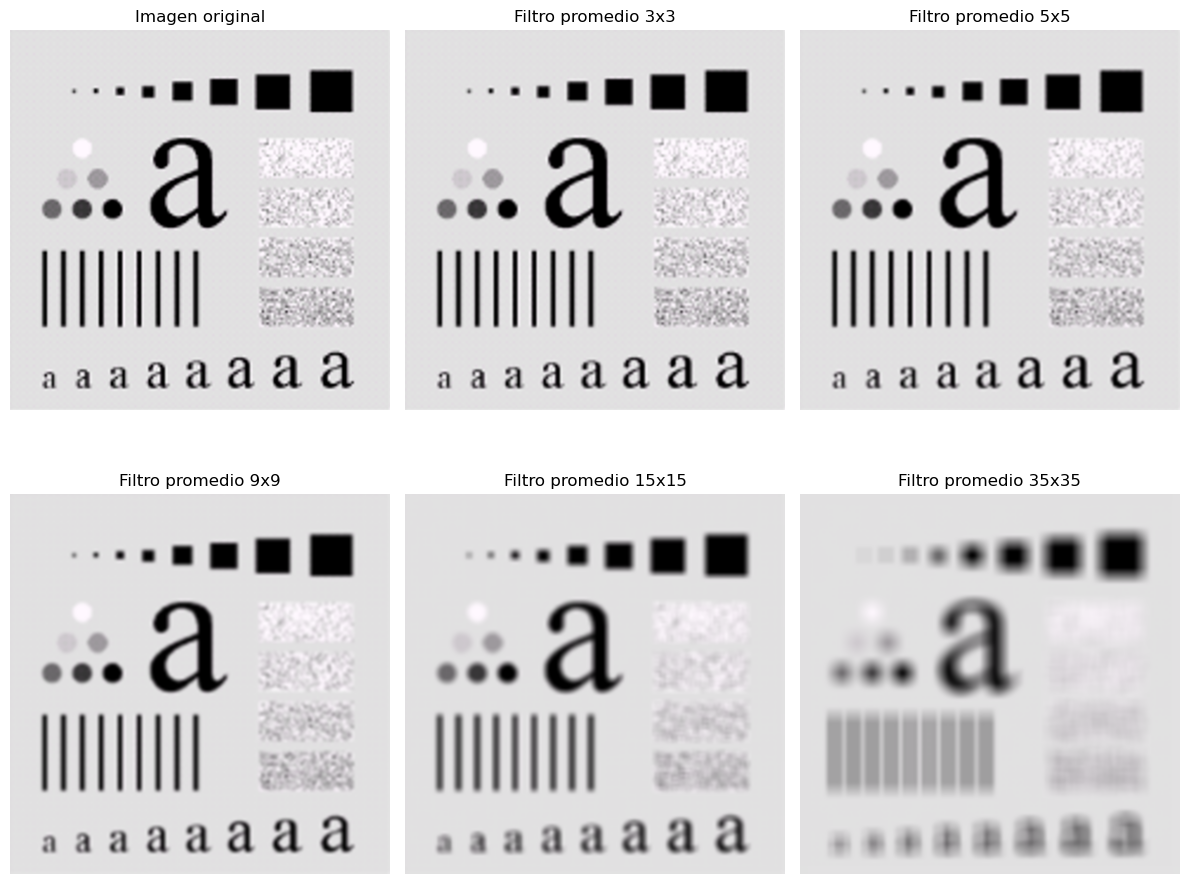

In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# --- Cargar imagen ---
img_path = 'fig/Notebook/Ejemplo1.png'
img = cv2.imread(img_path)

if img is None:
    raise FileNotFoundError(f"No se encontró la imagen en la ruta: {img_path}")

# Convertir de BGR (OpenCV) a RGB (para matplotlib)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# --- Definir tamaños de ventana ---
kernel_sizes = [3, 5, 9, 15, 35]

# --- Aplicar filtros de suavizado ---
blurred_images = []
for k in kernel_sizes:
    blur = cv2.blur(img_rgb, (k, k))
    blurred_images.append(blur)

# --- Crear la figura con subplots ---
fig, axes = plt.subplots(2, 3, figsize=(12, 10))
axes = axes.ravel()  # Aplanar arreglo 2D de ejes

# --- Mostrar la imagen original ---
axes[0].imshow(img_rgb)
axes[0].set_title("Imagen original")
axes[0].axis('off')

# --- Mostrar las imágenes suavizadas ---
for i, (k, blur) in enumerate(zip(kernel_sizes, blurred_images)):
    axes[i+1].imshow(blur)
    axes[i+1].set_title(f"Filtro promedio {k}x{k}")
    axes[i+1].axis('off')

# --- Ocultar el último subplot si no se usa ---
if len(kernel_sizes) + 1 < len(axes):
    axes[-1].axis('off')

plt.tight_layout()
plt.show()


## Filtro Gaussiano

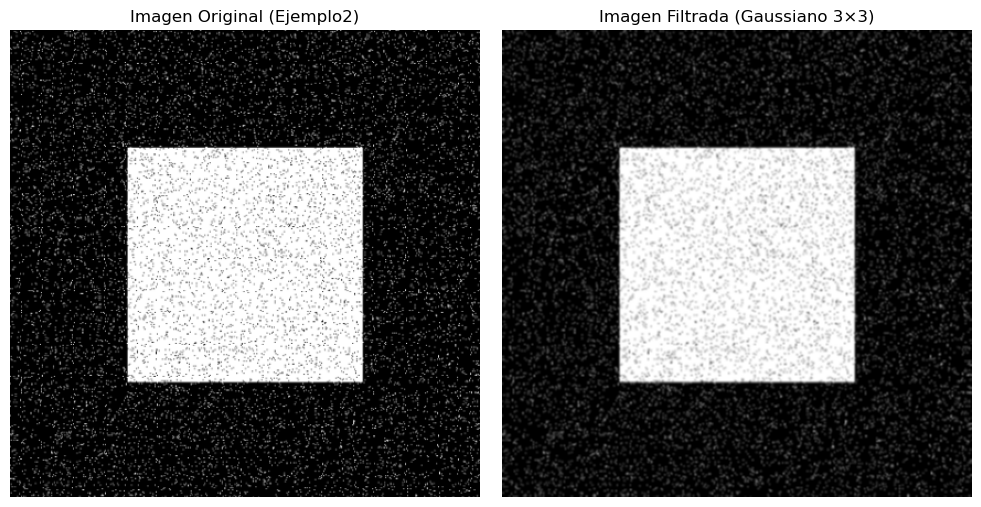

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- Cargar imagen ---
img_path = 'fig/Notebook/Ejemplo2.png'
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"No se encontró la imagen: {img_path}")

# --- Definir la máscara gaussiana 3x3 ---
gaussian_kernel = (1/16) * np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32)

# --- Aplicar convolución con la máscara gaussiana ---
gaussian_filtered = cv2.filter2D(img, -1, gaussian_kernel)

# --- Mostrar resultados ---
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img, cmap='gray')
axes[0].set_title("Imagen Original (Ejemplo2)")
axes[0].axis("off")

axes[1].imshow(gaussian_filtered, cmap='gray')
axes[1].set_title("Imagen Filtrada (Gaussiano 3×3)")
axes[1].axis("off")

plt.tight_layout()
plt.show()


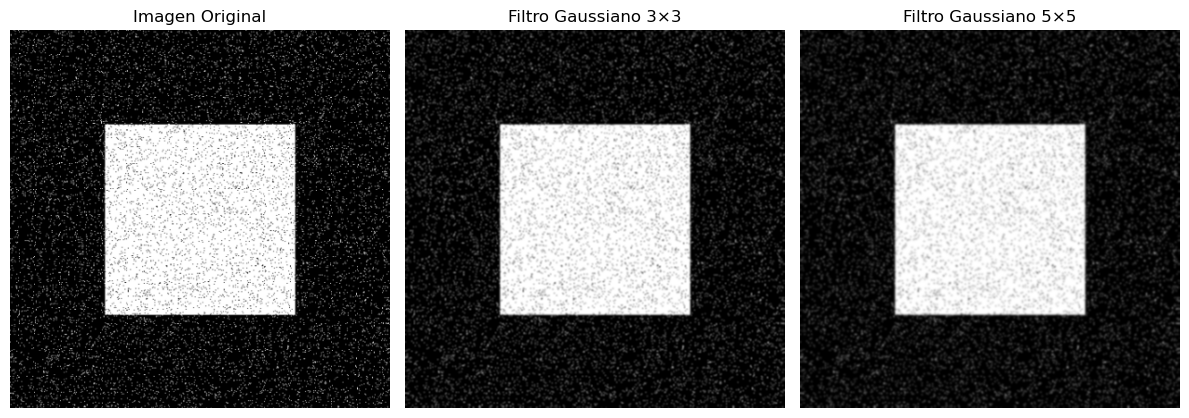

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- Cargar imagen ---
img_path = 'fig/Notebook/Ejemplo2.png'
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"No se encontró la imagen: {img_path}")

# --- Máscara gaussiana 3x3 explícita ---
gaussian_kernel_3x3 = (1/16) * np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32)

# --- Filtro gaussiano 5x5 generado ---
# getGaussianKernel genera un vector 1D gaussiano, lo multiplicamos para formar el 2D
g1d = cv2.getGaussianKernel(5, sigma=1)
gaussian_kernel_5x5 = g1d @ g1d.T  # producto externo -> kernel 2D

# --- Aplicar los filtros ---
filtered_3x3 = cv2.filter2D(img, -1, gaussian_kernel_3x3)
filtered_5x5 = cv2.filter2D(img, -1, gaussian_kernel_5x5)

# --- Mostrar resultados ---
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

titles = [
    "Imagen Original",
    "Filtro Gaussiano 3×3",
    "Filtro Gaussiano 5×5"
]
images = [img, filtered_3x3, filtered_5x5]

for ax, im, title in zip(axes, images, titles):
    ax.imshow(im, cmap='gray')
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


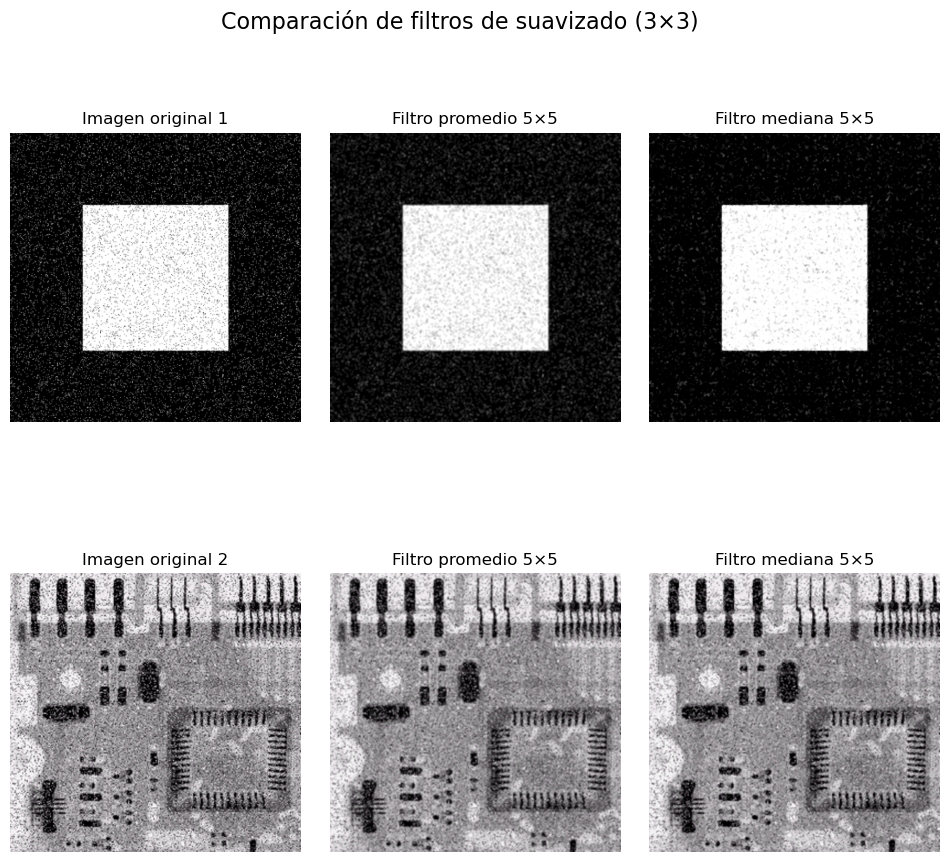

In [5]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# --- Rutas de las imágenes ---
image_paths = [
    'fig/Notebook/Ejemplo2.png',
    'fig/Notebook/Ejemplo3.png'
]

# --- Leer y convertir las imágenes a RGB ---
images = []
for path in image_paths:
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"No se encontró la imagen: {path}")
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    images.append(img_rgb)

# --- Aplicar filtros ---
mean_filtered = [cv2.blur(img, (3, 3)) for img in images]
median_filtered = [cv2.medianBlur(img, 3) for img in images]

# --- Crear figura con subplots 3x3 ---
fig, axes = plt.subplots(2, 3, figsize=(12, 10))
plt.subplots_adjust(wspace=0.1, hspace=0.3)

titles = [
    "Imagen original", "Filtro promedio 5×5", "Filtro mediana 5×5"
]

# --- Mostrar resultados ---
for i in range(2):  # Una fila por imagen
    axes[i, 0].imshow(images[i])
    axes[i, 0].set_title(f"{titles[0]} {i+1}")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(mean_filtered[i])
    axes[i, 1].set_title(titles[1])
    axes[i, 1].axis('off')

    axes[i, 2].imshow(median_filtered[i])
    axes[i, 2].set_title(titles[2])
    axes[i, 2].axis('off')

plt.suptitle("Comparación de filtros de suavizado (3×3)", fontsize=16)
plt.show()


## Filtros derivativos
- Filtro Laplaciano

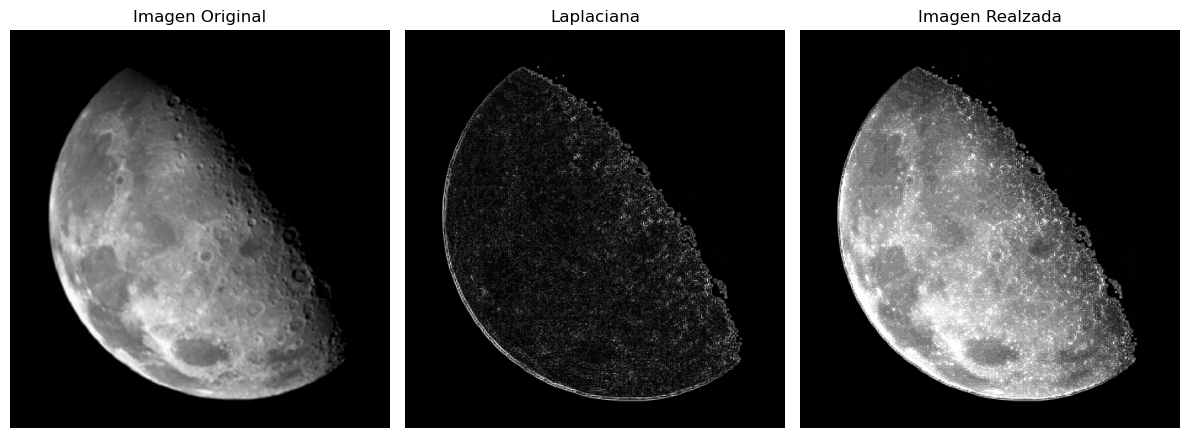

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- Cargar imagen ---
img_path = 'fig/Notebook/Luna.png'
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"No se encontró la imagen: {img_path}")

# --- Calcular Laplaciana ---
laplacian = cv2.Laplacian(img, cv2.CV_64F, ksize=3)
laplacian = cv2.convertScaleAbs(laplacian)

# --- Realce: sumar la Laplaciana a la imagen original ---
realzada = cv2.addWeighted(img, 1.0, laplacian, 1.0, 0)

# --- Mostrar resultados ---
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
titles = ['Imagen Original', 'Laplaciana', 'Imagen Realzada']

for ax, im, title in zip(axes, [img, laplacian, realzada], titles):
    ax.imshow(im, cmap='gray')
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()


## Filtro de Sobel

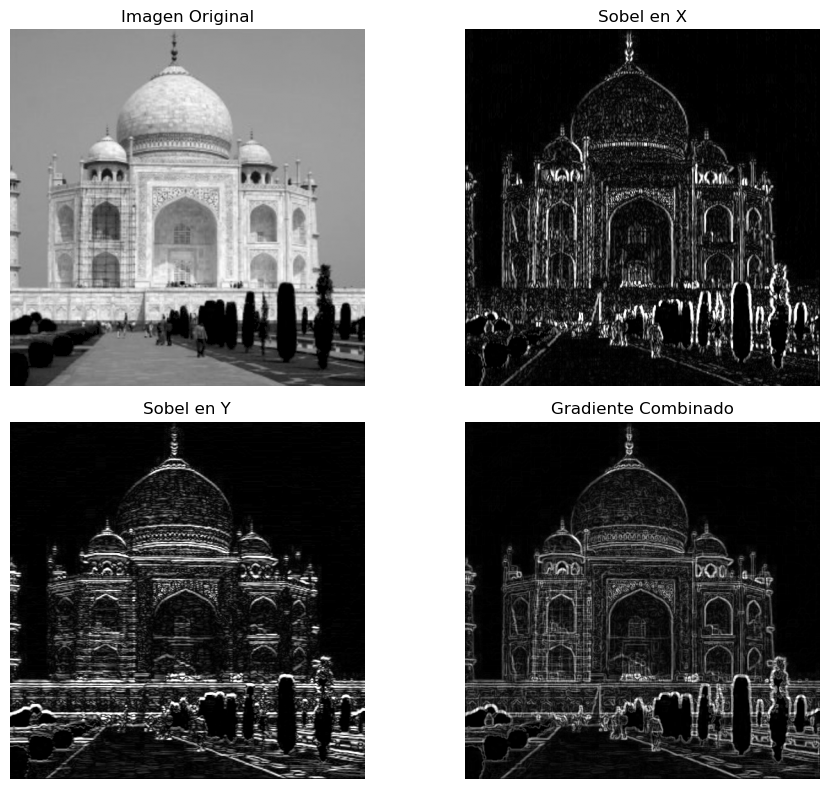

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- Cargar imagen ---
img_path = 'fig/Notebook/Mezquita.png'
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"No se encontró la imagen: {img_path}")

# --- Aplicar filtro de Sobel ---
sobelx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

# Convertir a escala de 8 bits para visualización
sobelx_abs = cv2.convertScaleAbs(sobelx)
sobely_abs = cv2.convertScaleAbs(sobely)

# Magnitud del gradiente (combinación de ambos)
sobel_combined = cv2.addWeighted(sobelx_abs, 0.5, sobely_abs, 0.5, 0)

# --- Mostrar resultados ---
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
titles = [
    'Imagen Original',
    'Sobel en X',
    'Sobel en Y',
    'Gradiente Combinado'
]
images = [img, sobelx_abs, sobely_abs, sobel_combined]

for ax, im, title in zip(axes.flat, images, titles):
    ax.imshow(im, cmap='gray')
    ax.set_title(title)
    ax.axis('off')

plt.tight_layout()
plt.show()


## Filtro de Canny

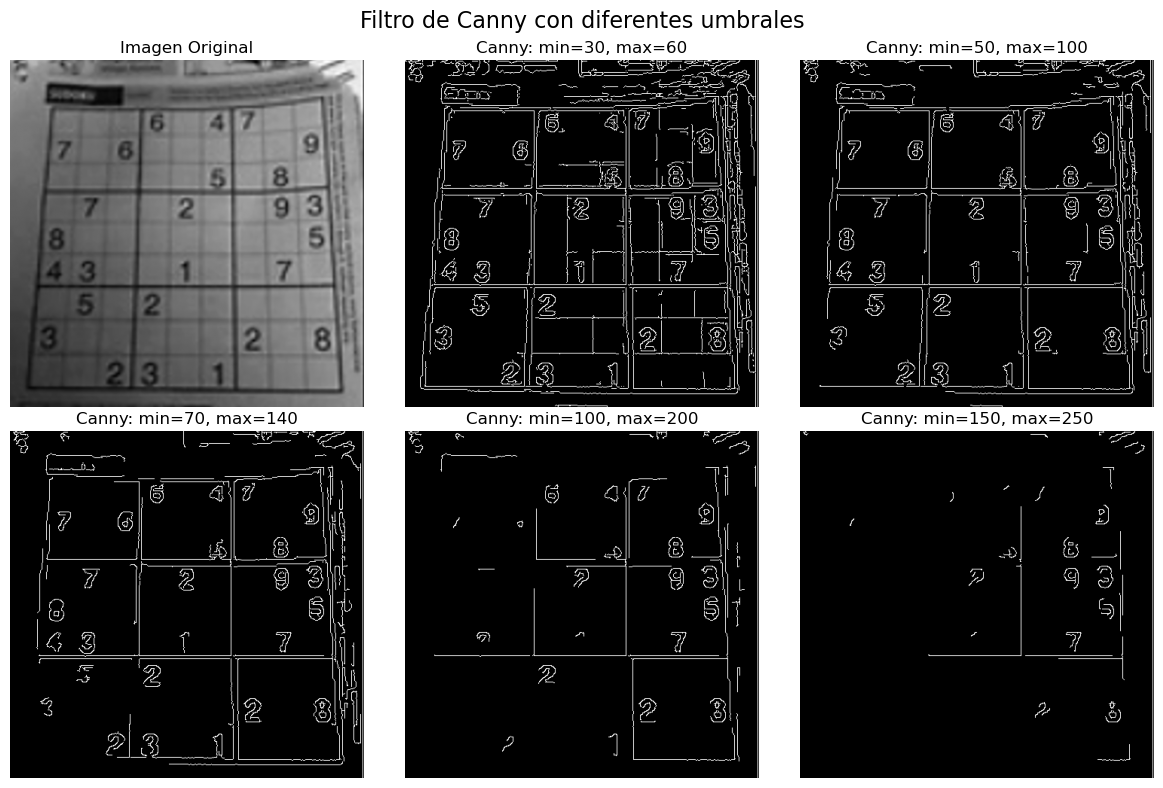

In [8]:
import cv2
import matplotlib.pyplot as plt

# --- Cargar imagen ---
img_path = 'fig/Notebook/Sudoku.png'
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"No se encontró la imagen: {img_path}")

# --- Definir combinaciones de umbrales (min, max) ---
thresholds = [
    (30, 60),
    (50, 100),
    (70, 140),
    (100, 200),
    (150, 250)
]

# --- Aplicar Canny ---
edges = [cv2.Canny(img, t1, t2) for (t1, t2) in thresholds]

# --- Crear figura 2x3 ---
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

# Primera imagen: original
axes[0, 0].imshow(img, cmap='gray')
axes[0, 0].set_title('Imagen Original')
axes[0, 0].axis('off')

# Siguientes imágenes: resultados Canny
for ax, edge_img, (t1, t2) in zip(axes.flat[1:], edges, thresholds):
    ax.imshow(edge_img, cmap='gray')
    ax.set_title(f'Canny: min={t1}, max={t2}')
    ax.axis('off')

# Quitar subplots vacíos si los hubiera
for ax in axes.flat[len(edges)+1:]:
    ax.axis('off')

plt.suptitle('Filtro de Canny con diferentes umbrales', fontsize=16)
plt.tight_layout()
plt.show()


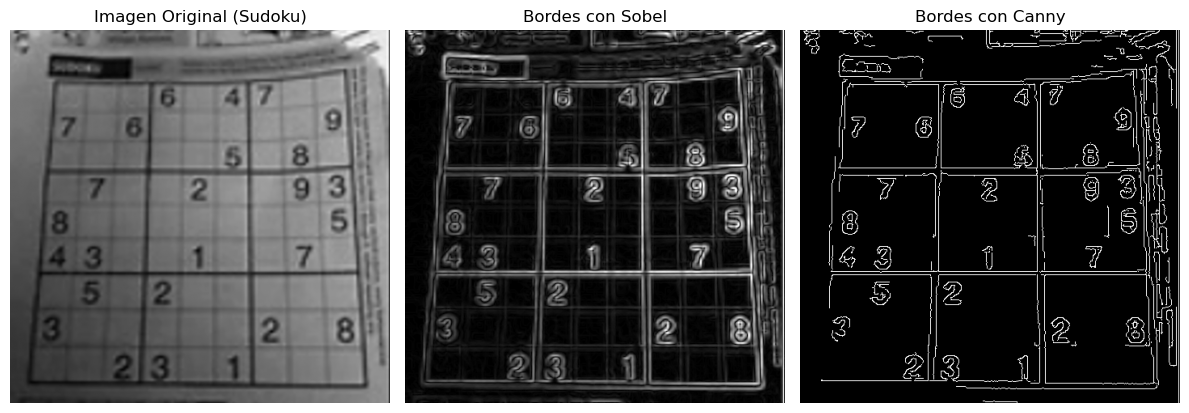

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- Cargar imagen ---
img_path = 'fig/Notebook/Sudoku.png'
img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError(f"No se encontró la imagen: {img_path}")

# --- Filtro Sobel ---
sobelx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
sobel_combined = cv2.magnitude(sobelx, sobely)
sobel_combined = cv2.convertScaleAbs(sobel_combined)

# --- Filtro Canny ---
edges_canny = cv2.Canny(img, 50, 100)

# --- Mostrar resultados ---
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

titles = [
    "Imagen Original (Sudoku)",
    "Bordes con Sobel",
    "Bordes con Canny"
]
images = [img, sobel_combined, edges_canny]

for ax, im, title in zip(axes, images, titles):
    ax.imshow(im, cmap='gray')
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


<div style="border: 2px solid #4CAF50; padding: 5px; border-radius: 4px; background-color: #e8f5e9; text-align: center;">
</div>

# **Morfológia Matemática en Imágenes**

## Carga de imágenes

In [10]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

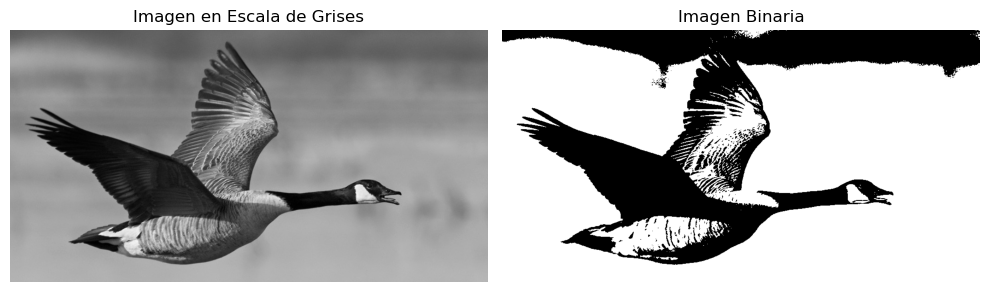

In [11]:
# Cargar la imagen (reemplaza 'tu_imagen.jpg' por el nombre de tu archivo)
imagen = cv2.imread('./fig/Notebook/Ganso.png')

# Convertir a escala de grises
gris1 = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

# Convertir a binaria (umbral automático con Otsu)
_, binaria1 = cv2.threshold(gris1, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Mostrar las imágenes
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gris1, cmap='gray')
plt.title('Imagen en Escala de Grises')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(binaria1, cmap='gray')
plt.title('Imagen Binaria')
plt.axis('off')

plt.tight_layout()
plt.show()

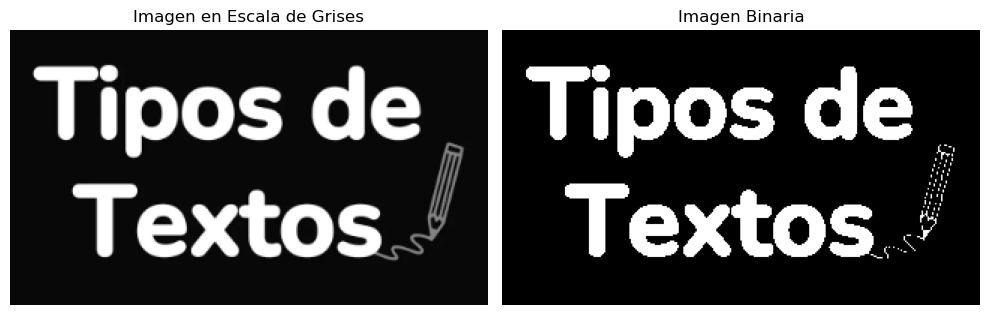

In [12]:
# Cargar la imagen (reemplaza 'tu_imagen.jpg' por el nombre de tu archivo)
imagen = cv2.imread('./fig/Notebook/Texto.png')

# Convertir a escala de grises
gris2 = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

# Convertir a binaria (umbral automático con Otsu)
_, binaria2 = cv2.threshold(gris2, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Mostrar las imágenes
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gris2, cmap='gray')
plt.title('Imagen en Escala de Grises')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(binaria2, cmap='gray')
plt.title('Imagen Binaria')
plt.axis('off')

plt.tight_layout()
plt.show()

## Elemetos estructurantes

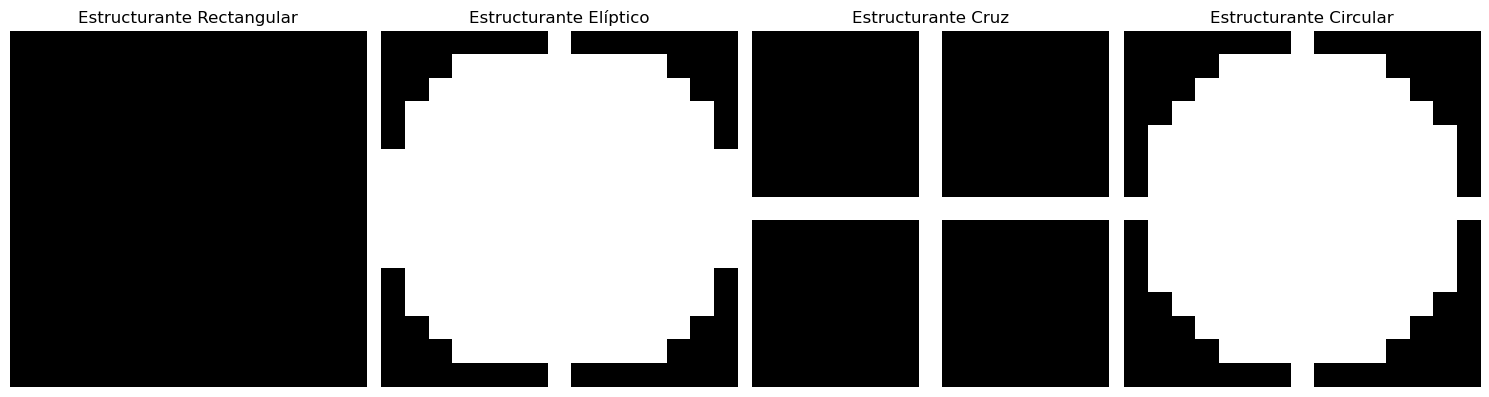

In [13]:
def crear_kernel_circular(diametro):
    """Crear un kernel circular binario de tamaño diametro x diametro."""
    radio = diametro // 2
    Y, X = np.ogrid[:diametro, :diametro]
    dist = (X - radio)**2 + (Y - radio)**2
    kernel = (dist <= radio**2).astype(np.uint8)
    return kernel

# Tamaño (impar para centro definido)
size = 15

# Crear kernels estándar de OpenCV
rect = cv2.getStructuringElement(cv2.MORPH_RECT, (size, size))
ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (size, size))

# Crear kernel circular personalizado
circular = crear_kernel_circular(size)

# Visualizar todos
estructurantes = [
    ('Rectangular', rect),
    ('Elíptico', ellipse),
    ('Cruz', cross),
    ('Circular', circular)
]

plt.figure(figsize=(15, 4))
for i, (nombre, kernel) in enumerate(estructurantes):
    plt.subplot(1, 4, i+1)
    plt.imshow(kernel, cmap='gray', interpolation='nearest')
    plt.title(f'Estructurante {nombre}')
    plt.axis('off')

plt.tight_layout()
plt.show()


## Erosión

In [14]:
# Crear elemento estructurante (3x3 rectangular)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
print(kernel)

[[1 1 1]
 [1 1 1]
 [1 1 1]]


findfont: Font family ['cmsy10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmr10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmtt10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmmi10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmb10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmss10'] not found. Falling back to DejaVu Sans.
findfont: Font family ['cmex10'] not found. Falling back to DejaVu Sans.


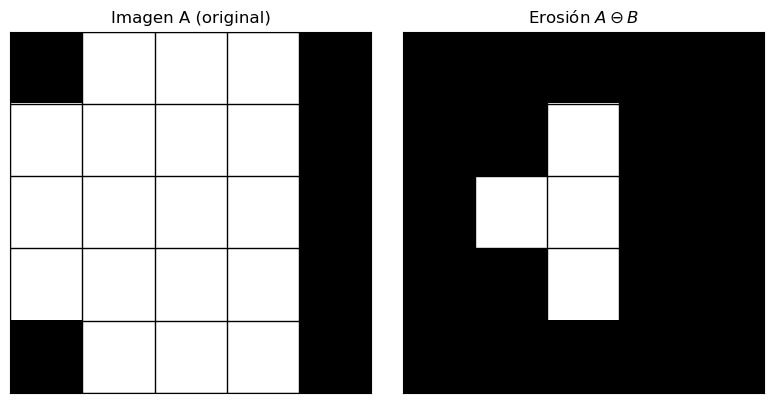

Resultado de A ⊖ B:
[[0 0 0 0 0]
 [0 0 1 0 0]
 [0 1 1 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]]


In [15]:
# Definir la imagen binaria A
A = np.array([
    [0, 1, 1, 1, 0],
    [1, 1, 1, 1, 0],
    [1, 1, 1, 1, 0],
    [1, 1, 1, 1, 0],
    [0, 1, 1, 1, 0]
], dtype=np.uint8)

# Definir el elemento estructurante B de 3x3
B = np.ones((3, 3), dtype=np.uint8)

# Aplicar erosión con padding cero fuera de la imagen
erosion = cv2.erode(A, B, anchor=(1, 1), borderType=cv2.BORDER_CONSTANT, borderValue=0)

# Función auxiliar para mostrar una matriz con cuadrícula
def mostrar_matriz_con_cuadricula(matriz, titulo, ax):
    ax.imshow(matriz, cmap='gray', vmin=0, vmax=1)
    ax.set_title(titulo)
    ax.set_xticks(np.arange(-0.5, matriz.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, matriz.shape[0], 1), minor=True)
    ax.grid(which='minor', color='black', linestyle='-', linewidth=1)
    ax.tick_params(which='both', bottom=False, left=False, labelbottom=False, labelleft=False)

# Mostrar resultados
fig, axs = plt.subplots(1, 2, figsize=(8, 4))
mostrar_matriz_con_cuadricula(A, 'Imagen A (original)', axs[0])
mostrar_matriz_con_cuadricula(erosion, 'Erosión $A \\ominus B$', axs[1])
plt.tight_layout()
plt.show()

# Imprimir resultado numérico
print("Resultado de A ⊖ B:")
print(erosion)


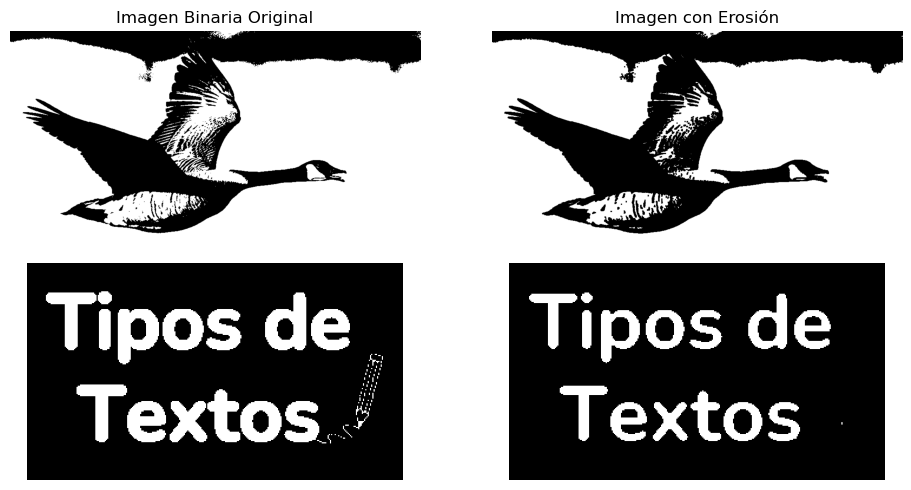

In [16]:
# Aplicar erosión
erosionada1 = cv2.erode(binaria1, kernel, iterations=1)
erosionada2 = cv2.erode(binaria2, kernel, iterations=1)

# Mostrar imágenes
plt.figure(figsize=(10, 5))

plt.subplot(2, 2, 1)
plt.imshow(binaria1, cmap='gray')
plt.title('Imagen Binaria Original')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(erosionada1, cmap='gray')
plt.title('Imagen con Erosión')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(binaria2, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(erosionada2, cmap='gray')
plt.axis('off')

plt.tight_layout()
#plt.savefig('./fig/Latex/resultado_erosion.png', bbox_inches='tight', dpi=300)
plt.show()

## Dilatación

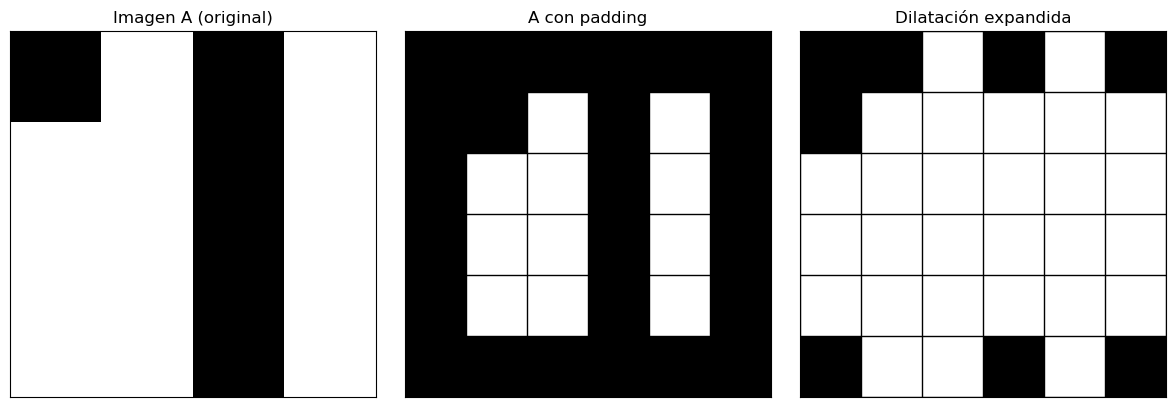

Resultado de A ⊕ B (con crecimiento):
[[0 0 1 0 1 0]
 [0 1 1 1 1 1]
 [1 1 1 1 1 1]
 [1 1 1 1 1 1]
 [1 1 1 1 1 1]
 [0 1 1 0 1 0]]


In [17]:
# Imagen original A
A = np.array([
    [0, 1, 0, 1],
    [1, 1, 0, 1],
    [1, 1, 0, 1],
    [1, 1, 0, 1]
], dtype=np.uint8)

# Elemento estructurante B (cruz)
B = np.array([
    [0, 1, 0],
    [1, 1, 1],
    [0, 1, 0]
], dtype=np.uint8)

# Padding de 1 píxel (mitad del tamaño del kernel) con ceros
A_padded = cv2.copyMakeBorder(A, 1, 1, 1, 1, borderType=cv2.BORDER_CONSTANT, value=0)

# Aplicar dilatación sobre la imagen extendida
dilatacion = cv2.dilate(A_padded, B, anchor=(1, 1), borderType=cv2.BORDER_CONSTANT, borderValue=0)

# Mostrar matriz original, con padding y resultado
def mostrar_matriz_con_cuadricula(matriz, titulo, ax):
    ax.imshow(matriz, cmap='gray', vmin=0, vmax=1)
    ax.set_title(titulo)
    ax.set_xticks(np.arange(-0.5, matriz.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, matriz.shape[0], 1), minor=True)
    ax.grid(which='minor', color='black', linestyle='-', linewidth=1)
    ax.tick_params(which='both', bottom=False, left=False, labelbottom=False, labelleft=False)

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
mostrar_matriz_con_cuadricula(A, 'Imagen A (original)', axs[0])
mostrar_matriz_con_cuadricula(A_padded, 'A con padding', axs[1])
mostrar_matriz_con_cuadricula(dilatacion, 'Dilatación expandida', axs[2])
plt.tight_layout()
plt.show()

# Mostrar resultado numérico
print("Resultado de A ⊕ B (con crecimiento):")
print(dilatacion)

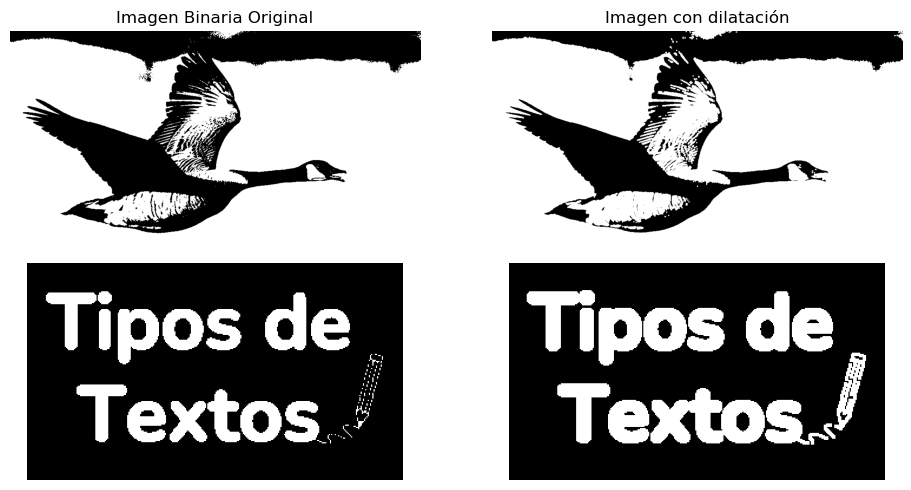

In [18]:
# Aplicar dilatación

dilatada1 = cv2.dilate(binaria1, kernel, iterations=1)
dilatada2 = cv2.dilate(binaria2, kernel, iterations=1)

# Mostrar imágenes
plt.figure(figsize=(10, 5))

plt.subplot(2, 2, 1)
plt.imshow(binaria1, cmap='gray')
plt.title('Imagen Binaria Original')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(dilatada1, cmap='gray')
plt.title('Imagen con dilatación')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(binaria2, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(dilatada2, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.savefig('./fig/Latex/resultado_dilatacion.png', bbox_inches='tight', dpi=300)
plt.show()

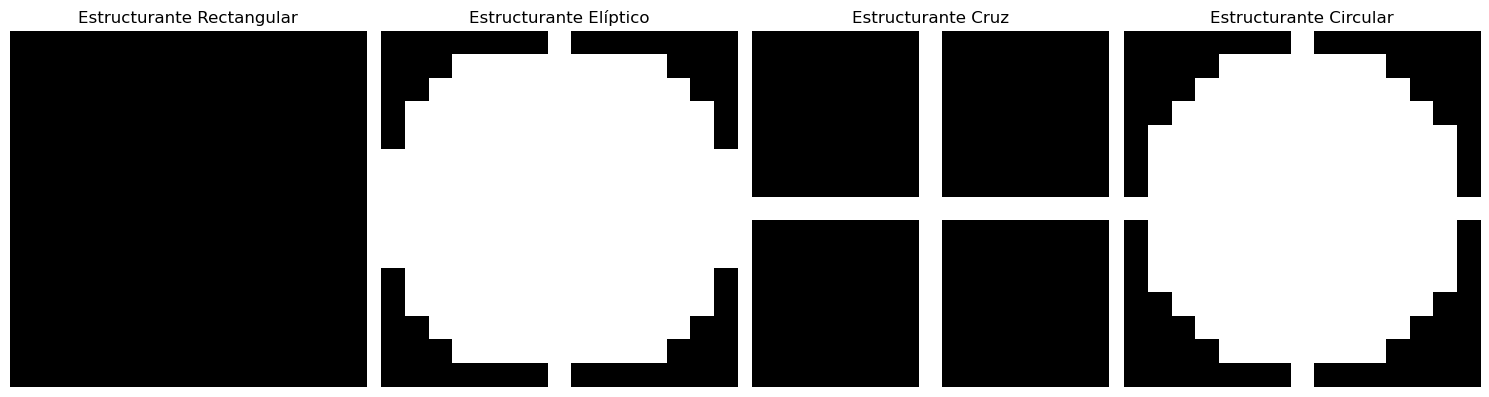

In [19]:
def crear_kernel_circular(diametro):
    """Crear un kernel circular binario de tamaño diametro x diametro."""
    radio = diametro // 2
    Y, X = np.ogrid[:diametro, :diametro]
    dist = (X - radio)**2 + (Y - radio)**2
    kernel = (dist <= radio**2).astype(np.uint8)
    return kernel

# Tamaño (impar para centro definido)
size = 15

# Crear kernels estándar de OpenCV
rect = cv2.getStructuringElement(cv2.MORPH_RECT, (size, size))
ellipse = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (size, size))
cross = cv2.getStructuringElement(cv2.MORPH_CROSS, (size, size))

# Crear kernel circular personalizado
circular = crear_kernel_circular(size)

# Visualizar todos
estructurantes = [
    ('Rectangular', rect),
    ('Elíptico', ellipse),
    ('Cruz', cross),
    ('Circular', circular)
]

plt.figure(figsize=(15, 4))
for i, (nombre, kernel) in enumerate(estructurantes):
    plt.subplot(1, 4, i+1)
    plt.imshow(kernel, cmap='gray', interpolation='nearest')
    plt.title(f'Estructurante {nombre}')
    plt.axis('off')

plt.tight_layout()
plt.show()


## Apertura

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import grey_erosion, grey_dilation
from scipy.ndimage import grey_opening

In [21]:
# Función para mostrar matriz con cuadrícula y valores numéricos
def mostrar_matriz_con_cuadricula_y_valores(matriz, titulo, ax):
    ax.imshow(matriz, cmap='gray', vmin=0, vmax=1)
    ax.set_title(titulo)
    ax.set_xticks(np.arange(-0.5, matriz.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, matriz.shape[0], 1), minor=True)
    ax.grid(which='minor', color='black', linestyle='-', linewidth=1)
    ax.tick_params(which='both', bottom=False, left=False, labelbottom=False, labelleft=False)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            color_texto = 'red' if matriz[i, j] == 1 else 'blue'
            ax.text(j, i, str(matriz[i, j]), ha='center', va='center', color=color_texto, fontsize=12)



Matriz A (Imagen Original):
[[0 0 1 0 0]
 [0 1 1 1 0]
 [1 1 1 1 1]
 [0 1 1 1 0]
 [0 0 1 0 0]]

Elemento Estructurante B:
[[1 1 1]
 [1 1 1]
 [1 1 1]]

Resultado de la Apertura:
[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]


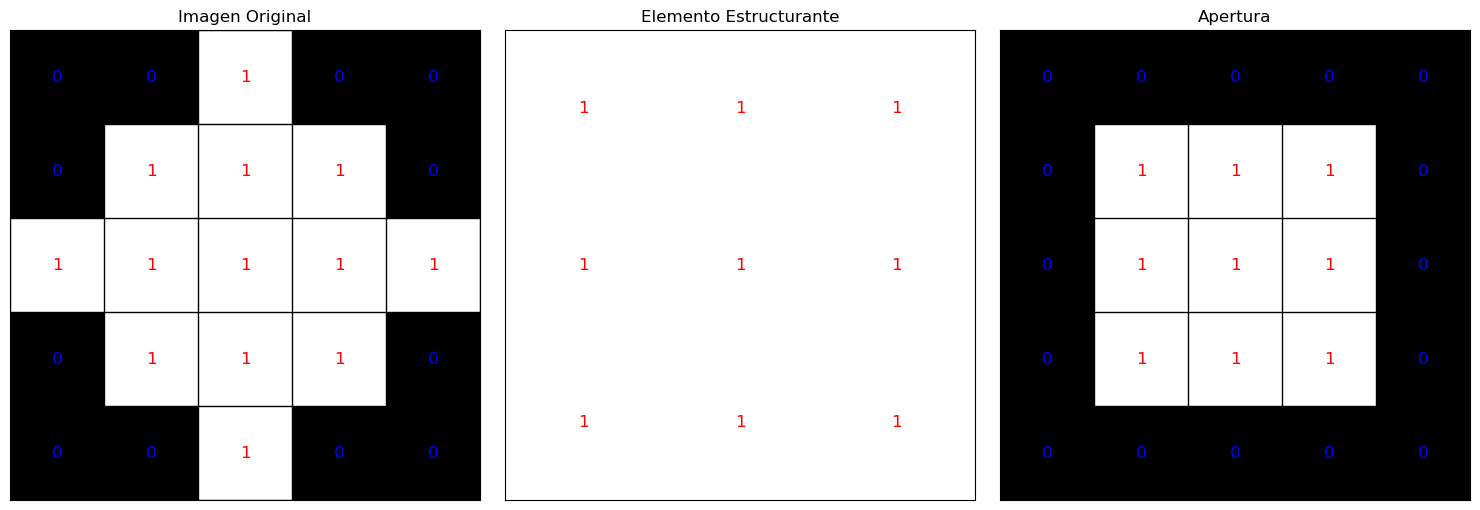

In [22]:
# Definición de la matriz A (5x5)
A = np.array([
    [0, 0, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [1, 1, 1, 1, 1],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 0, 0]
], dtype=int)

# Elemento estructurante normal 3x3 (todos unos)
B = np.ones((3, 3), dtype=int)

# Apertura morfológica
apertura = grey_opening(A, footprint=B, mode='constant', cval=0)

# Imprimir matrices en consola
print("Matriz A (Imagen Original):")
print(A)
print("\nElemento Estructurante B:")
print(B)
print("\nResultado de la Apertura:")
print(apertura)

# Visualización
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

mostrar_matriz_con_cuadricula_y_valores(A, 'Imagen Original', axes[0])
mostrar_matriz_con_cuadricula_y_valores(B, 'Elemento Estructurante', axes[1])
mostrar_matriz_con_cuadricula_y_valores(apertura, 'Apertura', axes[2])

plt.tight_layout()
plt.show()

### Paso a paso

Matriz A (Imagen Original):
[[0 0 1 0 0]
 [0 1 1 1 0]
 [1 1 1 1 1]
 [0 1 1 1 0]
 [0 0 1 0 0]]

Elemento Estructurante B:
[[1 1 1]
 [1 1 1]
 [1 1 1]]

Resultado de la erosión:
[[0 0 0 0 0]
 [0 0 0 0 0]
 [0 0 1 0 0]
 [0 0 0 0 0]
 [0 0 0 0 0]]

Resultado de la Apertura:
[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]


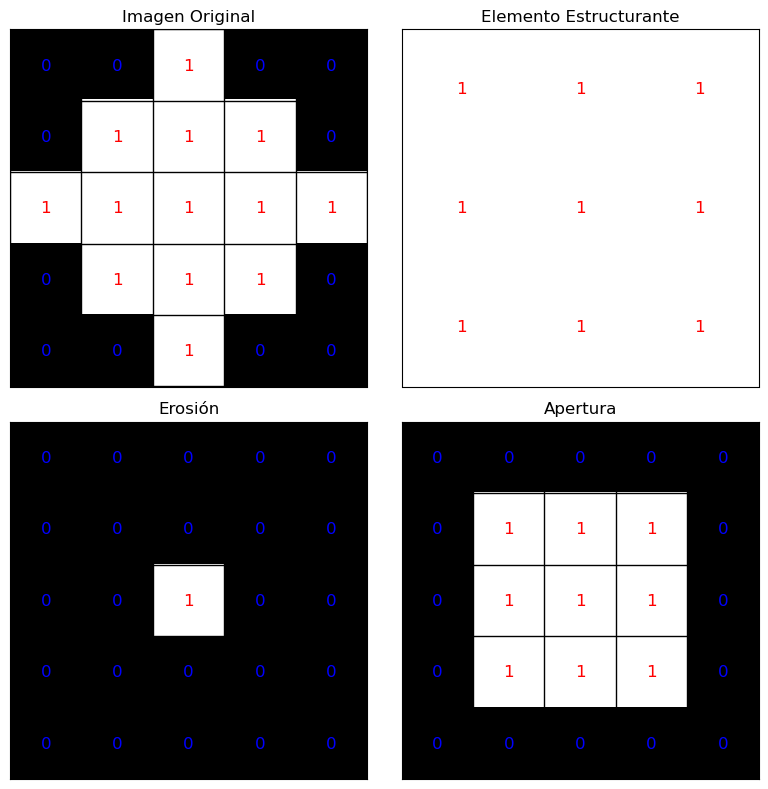

In [23]:
# Erosión con bordes en 0
erosion = grey_erosion(A, footprint=B, mode='constant', cval=0)

# Dilatación sobre el resultado de la erosión
apertura = grey_dilation(erosion, footprint=B, mode='constant', cval=0)


# Imprimir matrices en consola
print("Matriz A (Imagen Original):")
print(A)
print("\nElemento Estructurante B:")
print(B)
print("\nResultado de la erosión:")
print(erosion)
print("\nResultado de la Apertura:")
print(apertura)


# Visualización en 2 filas y 2 columnas
fig, axes = plt.subplots(2, 2, figsize=(8, 8))

titles = ['Imagen Original', 'Elemento Estructurante', 'Erosión', 'Apertura']
images = [A, B, erosion, apertura]

for ax, title, img in zip(axes.flatten(), titles, images):
    mostrar_matriz_con_cuadricula_y_valores(img, title, ax)

plt.tight_layout()
plt.show()

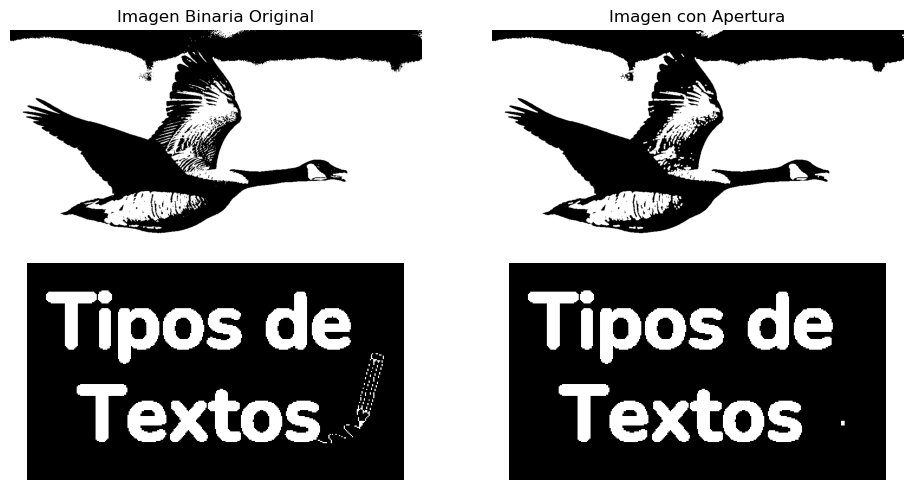

In [24]:
# Crear un elemento estructurante (se puede cambiar la forma y tamaño)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

# Aplicar apertura
apertura1 = cv2.morphologyEx(binaria1, cv2.MORPH_OPEN, kernel)
apertura2 = cv2.morphologyEx(binaria2, cv2.MORPH_OPEN, kernel)

# Mostrar imágenes
plt.figure(figsize=(10, 5))

plt.subplot(2, 2, 1)
plt.imshow(binaria1, cmap='gray')
plt.title('Imagen Binaria Original')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(apertura1, cmap='gray')
plt.title('Imagen con Apertura')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(binaria2, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(apertura2, cmap='gray')
plt.axis('off')

plt.tight_layout()
#plt.savefig('./fig/Latex/resultado_apertura.png', bbox_inches='tight', dpi=300)
plt.show()

## Cierre

Matriz A (Imagen Original):
[[0 0 0 0 0]
 [0 0 1 1 0]
 [0 1 0 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]

Elemento Estructurante B:
[[1 1 1]
 [1 1 1]
 [1 1 1]]

Resultado del cierre:
[[0 0 1 1 1]
 [0 0 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


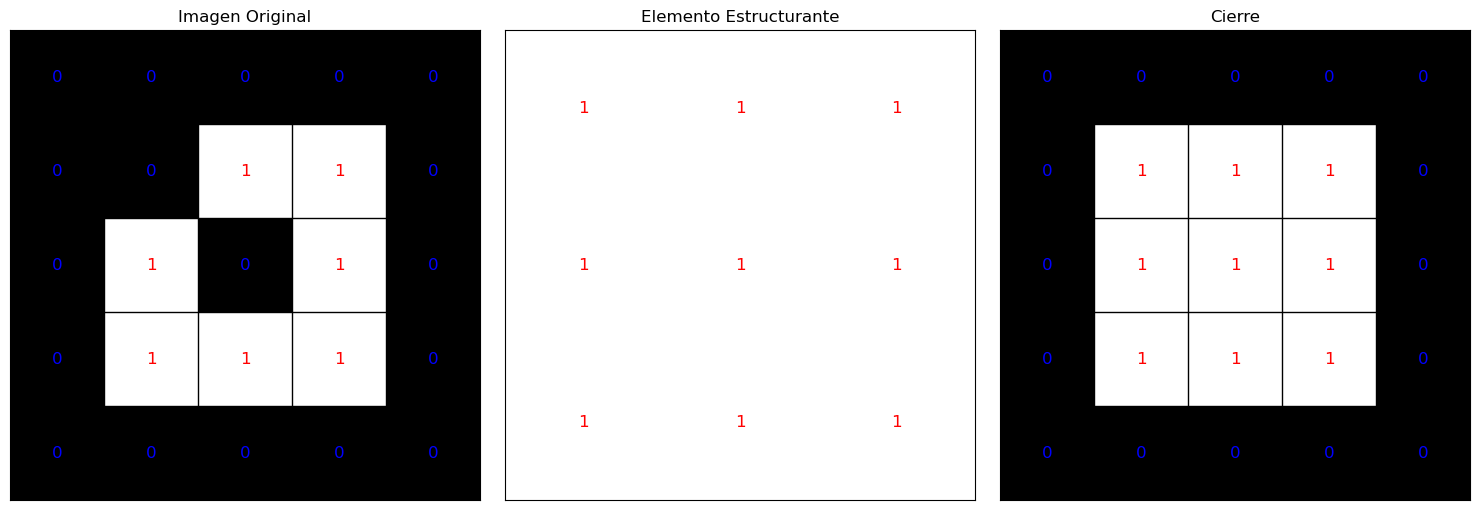

In [25]:
# Definición de la matriz A (5x5)
# Crear matriz binaria (valores 0 y 1)
A = np.array([
    [0, 0, 0, 0, 0],
    [0, 0, 1, 1, 0],
    [0, 1, 0, 1, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 0, 0, 0]
], dtype=np.uint8)

# Elemento estructurante normal 3x3 (todos unos)
B = np.ones((3, 3), dtype=np.uint8)

# Aplicar el cierre morfológico
cierre = cv2.morphologyEx(A, cv2.MORPH_CLOSE, B)

# Imprimir matrices en consola
print("Matriz A (Imagen Original):")
print(A)
print("\nElemento Estructurante B:")
print(B)
print("\nResultado del cierre:")
print(cierre)

# Visualización
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

mostrar_matriz_con_cuadricula_y_valores(A, 'Imagen Original', axes[0])
mostrar_matriz_con_cuadricula_y_valores(B, 'Elemento Estructurante', axes[1])
mostrar_matriz_con_cuadricula_y_valores(apertura, 'Cierre', axes[2])

plt.tight_layout()
plt.show()

### Paso a paso

Matriz A (Imagen Original):
[[0 0 0 0 0]
 [0 0 1 1 0]
 [0 1 0 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]

Elemento Estructurante B:
[[1 1 1]
 [1 1 1]
 [1 1 1]]

Resultado de la dilatación:
[[0 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]

Resultado del cierre:
[[0 0 1 1 1]
 [0 0 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


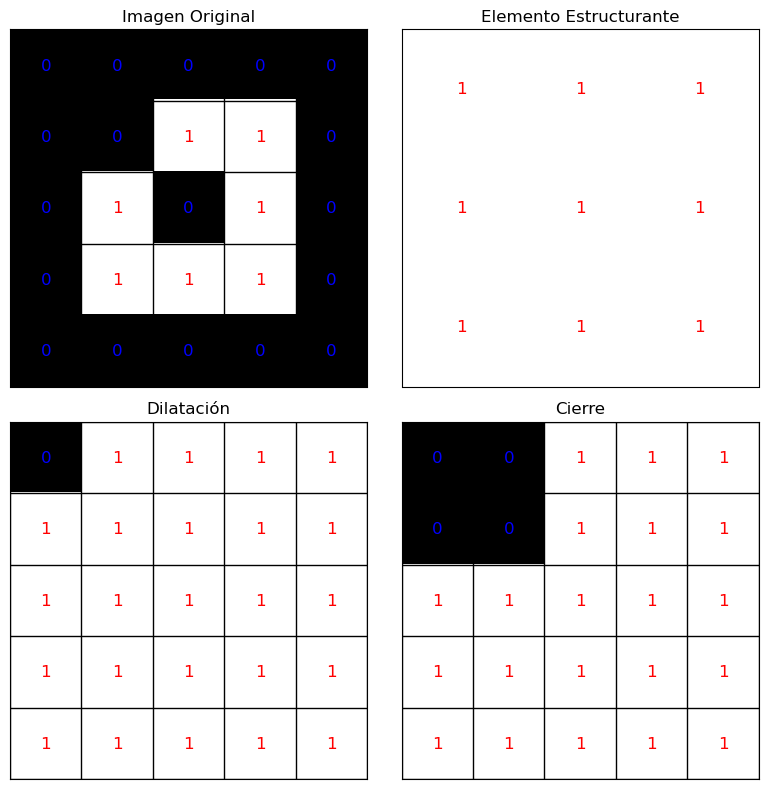

In [26]:
# Aplicar dilatación
dilatada = cv2.dilate(A, B)

# Aplicar erosión
cierre = cv2.erode(dilatada, B)



# Imprimir matrices en consola
print("Matriz A (Imagen Original):")
print(A)
print("\nElemento Estructurante B:")
print(B)
print("\nResultado de la dilatación:")
print(dilatada)
print("\nResultado del cierre:")
print(cierre)


# Visualización en 2 filas y 2 columnas
fig, axes = plt.subplots(2, 2, figsize=(8, 8))

titles = ['Imagen Original', 'Elemento Estructurante', 'Dilatación', 'Cierre']
images = [A, B, dilatada, cierre]

for ax, title, img in zip(axes.flatten(), titles, images):
    mostrar_matriz_con_cuadricula_y_valores(img, title, ax)

plt.tight_layout()
plt.show()

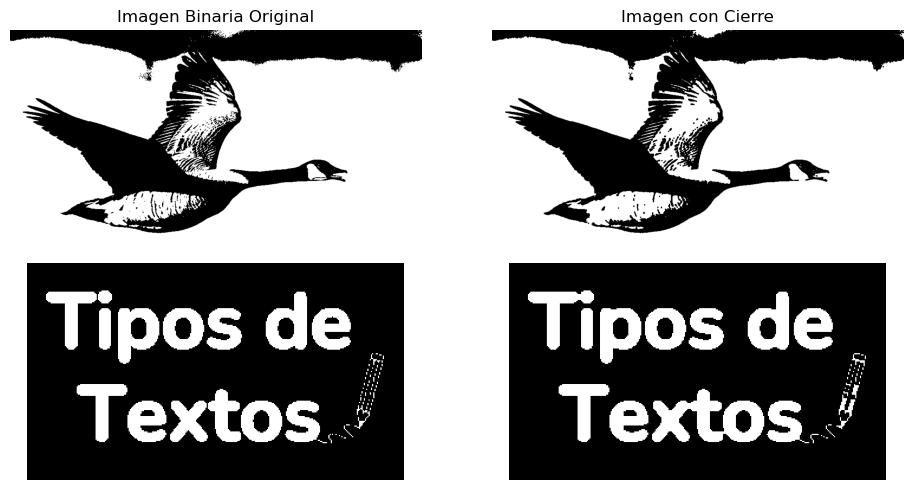

In [27]:
# Crear un elemento estructurante (se puede cambiar la forma y tamaño)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

# Aplicar apertura
cierre1 = cv2.morphologyEx(binaria1, cv2.MORPH_CLOSE, kernel)
cierre2 = cv2.morphologyEx(binaria2, cv2.MORPH_CLOSE, kernel)

# Mostrar imágenes
plt.figure(figsize=(10, 5))

plt.subplot(2, 2, 1)
plt.imshow(binaria1, cmap='gray')
plt.title('Imagen Binaria Original')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(cierre1, cmap='gray')
plt.title('Imagen con Cierre')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(binaria2, cmap='gray')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(cierre2, cmap='gray')
plt.axis('off')

plt.tight_layout()
#plt.savefig('./fig/Latex/resultado_cierre.png', bbox_inches='tight', dpi=300)
plt.show()

### Letra con ruido en blanco y negro

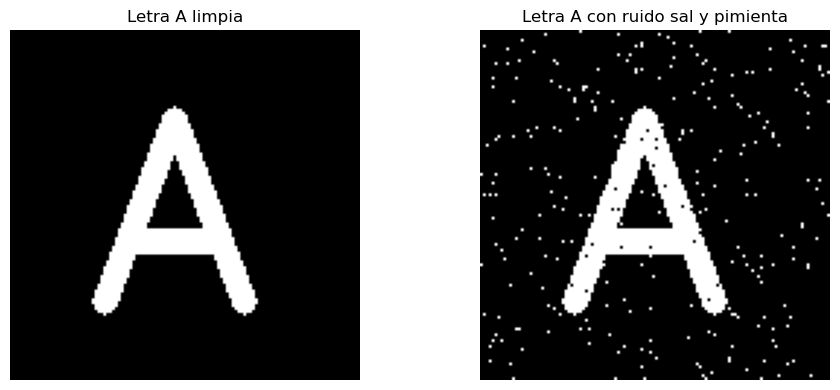

In [28]:
# Crear una imagen negra (fondo)
imagen = np.zeros((100, 100), dtype=np.uint8)

# Dibujar una letra blanca ('A')
cv2.putText(imagen, 'A', (20, 70), cv2.FONT_HERSHEY_SIMPLEX, 2, 255, 3, cv2.LINE_AA)

# Crear un lienzo más grande
alto, ancho = 120, 120
imagen = np.zeros((alto, ancho), dtype=np.uint8)

# Configurar fuente y tamaño
fuente = cv2.FONT_HERSHEY_SIMPLEX
escala = 3              # Tamaño de la letra (más grande)
grosor = 7              # Letra más ancha

# Obtener tamaño de la letra para centrarla
(texto_ancho, texto_alto), _ = cv2.getTextSize('A', fuente, escala, grosor)

# Calcular coordenadas para centrar
x = (ancho - texto_ancho) // 2
y = (alto + texto_alto) // 2

# Dibujar letra centrada
cv2.putText(imagen, 'A', (x, y), fuente, escala, 255, grosor, cv2.LINE_8)




#------------------------------------
# Copiar la imagen para añadir ruido
imagen_ruidosa = imagen.copy()

# Parámetros del ruido
porcentaje_ruido = 0.02  # 2% de píxeles afectados

# Calcular número de píxeles a alterar
num_pixeles = int(porcentaje_ruido * imagen.size)

# Coordenadas aleatorias para puntos blancos (sal)
coords_sal = (np.random.randint(0, imagen.shape[0], num_pixeles),
              np.random.randint(0, imagen.shape[1], num_pixeles))
imagen_ruidosa[coords_sal] = 255

# Coordenadas aleatorias para puntos negros (pimienta)
coords_pimienta = (np.random.randint(0, imagen.shape[0], num_pixeles),
                   np.random.randint(0, imagen.shape[1], num_pixeles))
imagen_ruidosa[coords_pimienta] = 0

# Mostrar resultados
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.title('Letra A limpia')
plt.imshow(imagen, cmap='gray')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title('Letra A con ruido sal y pimienta')
plt.imshow(imagen_ruidosa, cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()

### Filtro morfológico
- Apertura seguida de cierre

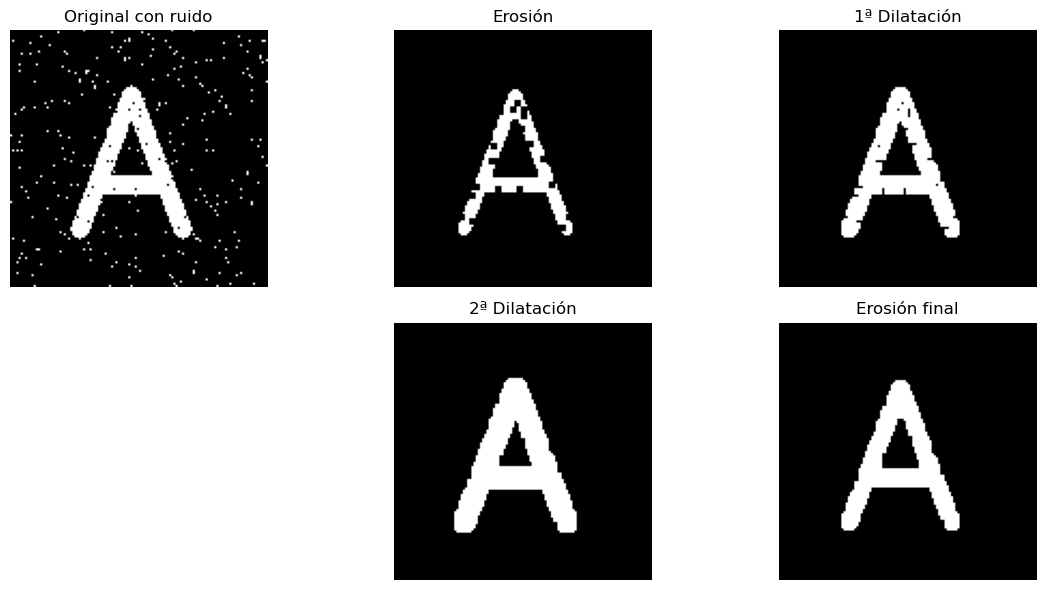

In [29]:
# Crear elemento estructurante (kernel)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

# Aplicar operaciones morfológicas paso a paso
paso1 = cv2.erode(imagen_ruidosa, kernel)       # Erosión
paso2 = cv2.dilate(paso1, kernel)               # Dilatación
paso3 = cv2.dilate(paso2, kernel)               # Otra dilatación
paso4 = cv2.erode(paso3, kernel)                # Erosión final

# imágenes y títulos
imagenes = [imagen_ruidosa, paso1, paso2, paso3, paso4]
titulos = ['Original con ruido', 'Erosión', '1ª Dilatación', '2ª Dilatación', 'Erosión final']

plt.figure(figsize=(12, 6))

# Primera fila (3 imágenes)
for i in range(3):
    plt.subplot(2, 3, i + 1)
    plt.imshow(imagenes[i], cmap='gray')
    plt.title(titulos[i])
    plt.axis('off')

# Segunda fila (2 imágenes)
for i in range(2):
    plt.subplot(2, 3, i + 5)  # Saltar la celda vacía del centro si la quieres dejar libre
    plt.imshow(imagenes[i + 3], cmap='gray')
    plt.title(titulos[i + 3])
    plt.axis('off')

plt.tight_layout()
#plt.savefig('./fig/Latex/resultado_Filtro_Morfologico1.png', bbox_inches='tight', dpi=300)
plt.show()

- Cierre seguido de apertura

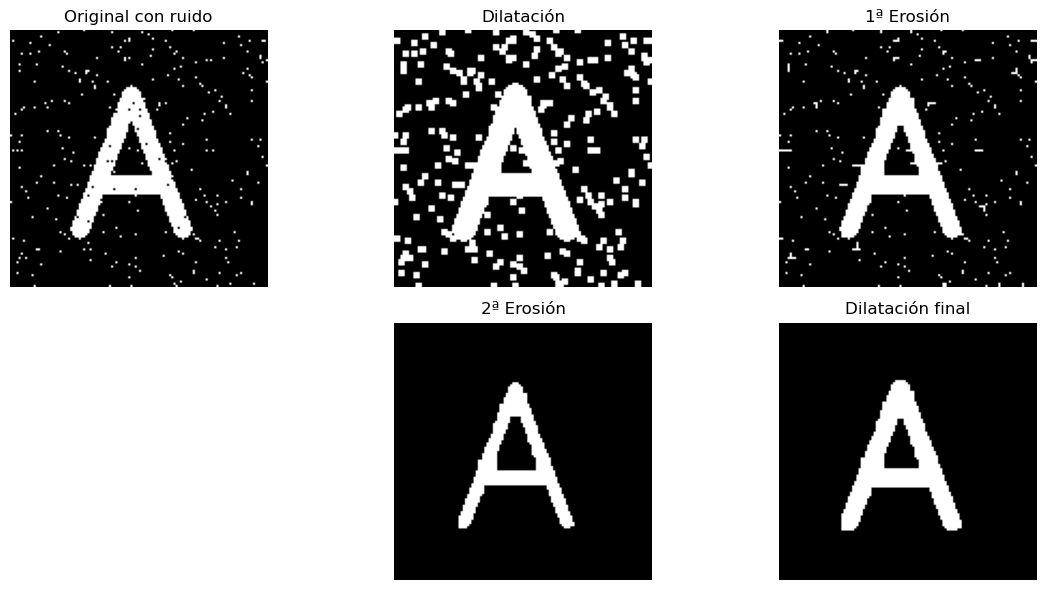

In [30]:
# Crear elemento estructurante (kernel)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

# Aplicar operaciones morfológicas paso a paso
paso1 = cv2.dilate(imagen_ruidosa, kernel)       # Erosión
paso2 = cv2.erode(paso1, kernel)               # Dilatación
paso3 = cv2.erode(paso2, kernel)               # Otra dilatación
paso4 = cv2.dilate(paso3, kernel)                # Erosión final

# imágenes y títulos
imagenes = [imagen_ruidosa, paso1, paso2, paso3, paso4]
titulos = ['Original con ruido', 'Dilatación', '1ª Erosión', '2ª Erosión', 'Dilatación final']

plt.figure(figsize=(12, 6))

# Primera fila (3 imágenes)
for i in range(3):
    plt.subplot(2, 3, i + 1)
    plt.imshow(imagenes[i], cmap='gray')
    plt.title(titulos[i])
    plt.axis('off')

# Segunda fila (2 imágenes)
for i in range(2):
    plt.subplot(2, 3, i + 5)  # Saltar la celda vacía del centro si la quieres dejar libre
    plt.imshow(imagenes[i + 3], cmap='gray')
    plt.title(titulos[i + 3])
    plt.axis('off')

plt.tight_layout()
#plt.savefig('./fig/Latex/resultado_Filtro_Morfologico2.png', bbox_inches='tight', dpi=300)
plt.show()

## Transformada Hit-or-Miss

In [31]:
import numpy as np
from scipy import ndimage
from scipy.ndimage import binary_dilation
from scipy.ndimage import binary_hit_or_miss

In [32]:
# Imagen original (0 y 255)
a = np.array([[0, 0, 0, 0, 0, 0, 0, 0],
              [0, 255, 255, 255, 0, 0, 0, 255],
              [0, 255, 255, 255, 0, 0, 0, 0],
              [0, 255, 255, 255, 0, 255, 0, 0],
              [0, 0, 255, 0, 0, 0, 0, 0],
              [0, 0, 255, 0, 0, 255, 255, 0],
              [0, 255, 0, 255, 0, 0, 255, 0],
              [0, 255, 255, 255, 0, 0, 0, 0]], dtype=np.uint8)

# Convertir a booleano
A = (a == 255)

# Crear la imagen complementada
Ac = np.logical_not(A)


# # Elementos estructurantes (coincidencia con blancos)
# b1 = np.array([[0, 1, 0],
#                [1, 0, 1],
#                [0, 1, 0]], dtype=bool)

# K=1
# # Elementos estructurantes (coincidencia con negros)
# b2 = np.array([[0, 0, 0],
#                [0, 1, 0],
#                [0, 0, 0]], dtype=bool)

b1 = np.array([[0, 0, 0], [1, 1, 0], [0, 1, 0]], dtype=bool)
K=2
b2 = np.array([[1, 1, 1], [0, 0, 1], [0, 0, 1]], dtype=bool)


#b1 = np.array([[0, 0, 0], [0, 0, 0], [1, 1, 1]], dtype=bool)
#K=3
#b2 = np.array([[0, 0, 0], [0, 1, 1], [0, 0, 0]], dtype=bool)


# Parte hit: coincidencias con s1 en A
hit = ndimage.binary_erosion(A, structure=b1)      # Parte positiva

# Parte miss: coincidencias con s2 en el complemento de A
miss = ndimage.binary_erosion(Ac, structure=b2)    # Parte negativa (sobre complemento)

# Intersección de ambas (hit-or-miss manual)
manual_hit_or_miss = np.logical_and(hit, miss)

# Resultado completo Operación hit-or-miss
sal = ndimage.binary_hit_or_miss(A, structure1=b1, structure2=b2).astype(int)


#Visualización matrices

print("Entrada (imagen A):")
print(a)

print("\nB1:")
print(b1.astype(int))

print("\nhit:")
print(hit.astype(int))

print("\nEntrada A complementada):")
print(Ac.astype(int))

print("\nB2:")
print(b2.astype(int))

print("\nmiss:")
print(miss.astype(int))

print("\nSalida manual:")
print(manual_hit_or_miss.astype(int))

      
print("\nSalida:")
print(sal)


Entrada (imagen A):
[[  0   0   0   0   0   0   0   0]
 [  0 255 255 255   0   0   0 255]
 [  0 255 255 255   0   0   0   0]
 [  0 255 255 255   0 255   0   0]
 [  0   0 255   0   0   0   0   0]
 [  0   0 255   0   0 255 255   0]
 [  0 255   0 255   0   0 255   0]
 [  0 255 255 255   0   0   0   0]]

B1:
[[0 0 0]
 [1 1 0]
 [0 1 0]]

hit:
[[0 0 0 0 0 0 0 0]
 [0 0 1 1 0 0 0 0]
 [0 0 1 1 0 0 0 0]
 [0 0 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]

Entrada A complementada):
[[1 1 1 1 1 1 1 1]
 [1 0 0 0 1 1 1 0]
 [1 0 0 0 1 1 1 1]
 [1 0 0 0 1 0 1 1]
 [1 1 0 1 1 1 1 1]
 [1 1 0 1 1 0 0 1]
 [1 0 1 0 1 1 0 1]
 [1 0 0 0 1 1 1 1]]

B2:
[[1 1 1]
 [0 0 1]
 [0 0 1]]

miss:
[[0 0 0 0 0 0 0 0]
 [0 0 0 1 1 1 0 0]
 [0 0 0 0 0 1 0 0]
 [0 0 0 0 0 1 1 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]

Salida manual:
[[0 0 0 0 0 0 0 0]
 [0 0 0 1 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 1 0]
 [0 

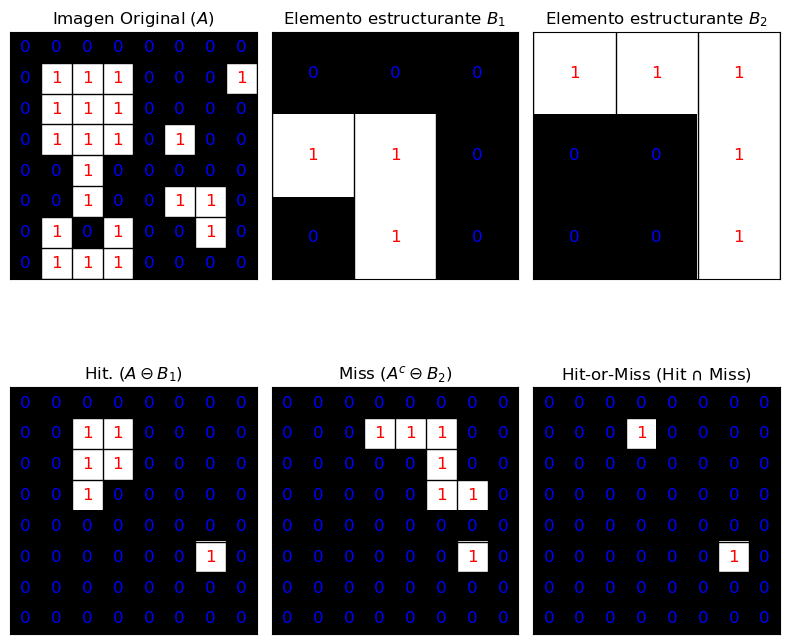

In [33]:
# Visualización en 2 filas y 3 columnas
fig, axes = plt.subplots(2, 3, figsize=(8, 8))

titles = ['Imagen Original ($A$)', 'Elemento estructurante $B_1$', 'Elemento estructurante $B_2$', 'Hit. ($A \ominus B_1$)', 'Miss ($A^c \ominus B_2$)', 'Hit-or-Miss (Hit $\cap$ Miss)']
images = [A.astype(int), b1.astype(int), b2.astype(int), hit.astype(int), miss.astype(int), sal]

for ax, title, img in zip(axes.flatten(), titles, images):
    mostrar_matriz_con_cuadricula_y_valores(img, title, ax)

plt.tight_layout()
# Guardar según el valor de K
#if K == 1: plt.savefig('./fig/Latex/resultado_Hit_Miss1.png', bbox_inches='tight', dpi=300)
#if K == 2: plt.savefig('./fig/Latex/resultado_Hit_Miss2.png', bbox_inches='tight', dpi=300)
#if K == 3: plt.savefig('./fig/Latex/resultado_Hit_Miss3.png', bbox_inches='tight', dpi=300)
plt.show()

## Algoritmos morfológicos

### Extracción de fronteras

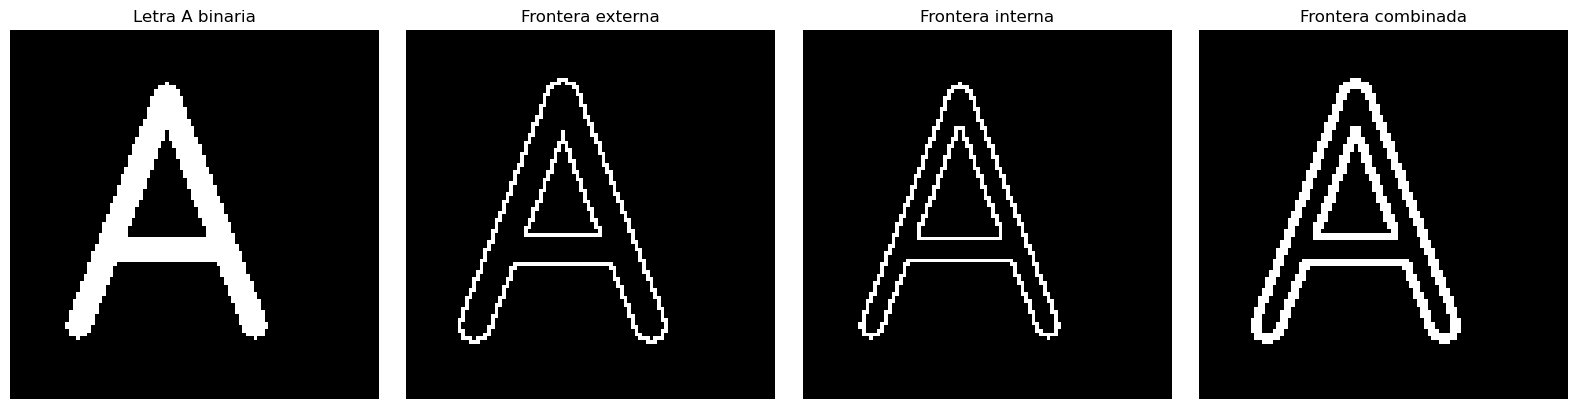

In [34]:
# 1. Crear una imagen binaria negra
imagen = np.zeros((100, 100), dtype=np.uint8)

# 2. Dibujar la letra 'A' en blanco (centrada y más ancha)
cv2.putText(imagen, 'A', (15, 80), cv2.FONT_HERSHEY_SIMPLEX, 3, 255, 5, cv2.LINE_8)

# 3. Convertir a binario booleano
A = (imagen == 255)

# 4. Elemento estructurante 3x3 cuadrado
B = np.ones((3, 3), dtype=bool)

# 5. Operaciones morfológicas
dilatada = ndimage.binary_dilation(A, structure=B)
erosionada = ndimage.binary_erosion(A, structure=B)

frontera_externa = dilatada & (~A)
frontera_interna = A & (~erosionada)
frontera_combinada = dilatada & (~erosionada)

# 6. Visualización
fig, axs = plt.subplots(1, 4, figsize=(16, 4))

axs[0].imshow(A, cmap='gray')
axs[0].set_title('Letra A binaria')
axs[0].axis('off')

axs[1].imshow(frontera_externa, cmap='gray')
axs[1].set_title('Frontera externa')
axs[1].axis('off')

axs[2].imshow(frontera_interna, cmap='gray')
axs[2].set_title('Frontera interna')
axs[2].axis('off')

axs[3].imshow(frontera_combinada, cmap='gray')
axs[3].set_title('Frontera combinada')
axs[3].axis('off')

plt.tight_layout()

# 7. Guardar si K == 1
K = 1
#if K == 1:    plt.savefig('./fig/Latex/frontera_morfologica_A.png', bbox_inches='tight', dpi=300)

plt.show()


### Adelgazamiento

**Elementos estructurantes para adelgazamiento**

El **adelgazamiento morfológico** se puede hacer como:

$$
A \leftarrow A \setminus \bigcup_i \left( A \circledast B_i \right)
$$

donde $ A \circledast B_i $ es la **operación *hit-or-miss*** con los pares $ (J_i, K_i) $.


In [35]:
# ---------------------------
# Función para imprimir B[i]
# ---------------------------
def imprimir_estructurante(B, nombre='B'):
    print(f'{nombre}:')
    for fila in B:
        print(' '.join('●' if v == 1 else '○' if v == 0 else ' ' for v in fila))
    print()

In [36]:
# ---------------------------
# Crear una imagen binaria de prueba
# ---------------------------
imagen = np.array([
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0],
    [0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 0],
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
], dtype=bool)


A = (imagen == 255)

In [37]:
# Función para imprimir matrices con 'X' en lugar de None
def imprimir_estructurante(matriz, nombre=""):
    print(f"{nombre}:")
    for fila in matriz:
        print(" ".join(str(x) if x is not None else 'X' for x in fila))
    print("-" * 30)

# ---------------------------
# Estructurantes para adelgazamiento
# Cada par: (foreground, background)
# ---------------------------
estructurantes = [
#B1
    (np.array([[0, 0, 0],
               [0, 1, 0],
               [1, 1, 1]], dtype=object),

     np.array([[1, 1, 1],
               [0, 0, 0],
               [0, 0, 0]], dtype=object)),

#B2
    (np.array([[0, 1, 1],
               [0, 0, 1],
               [0, 0, 0]], dtype=object),

     np.array([[0, 0, 0],
               [1, 1, 0],
               [1, 1, 0]], dtype=object)),

#B3
    (np.array([[1, 0, 0],
               [1, 1, 0],
               [1, 1, 0]], dtype=object),

     np.array([[0, 0, 1],
               [0, 0, 1],
               [0, 0, 1]], dtype=object)),

#B4
    (np.array([[1, 1, 0],
               [1, 1, 0],
               [0, 0, 0]], dtype=object),

     np.array([[0, 0, 0],
               [0, 0, 1],
               [0, 1, 1]], dtype=object)),

#B5
    (np.array([[1, 1, 1],
               [0, 1, 0],
               [0, 0, 0]], dtype=object),

     np.array([[0, 0, 0],
               [0, 0, 0],
               [1, 1, 1]], dtype=object)),

#B6
    (np.array([[0, 1, 1],
               [0, 1, 1],
               [0, 0, 0]], dtype=object),

     np.array([[0, 0, 0],
               [1, 0, 0],
               [1, 1, 0]], dtype=object)),

#B7
    (np.array([[0, 0, 1],
               [0, 1, 1],
               [0, 0, 1]], dtype=object),

     np.array([[1, 0, 0],
               [1, 0, 0],
               [1, 0, 0]], dtype=object)),

#B8
    (np.array([[0, 0, 0],
               [0, 1, 1],
               [0, 1, 1]], dtype=object),

     np.array([[1, 1, 0],
               [1, 0, 0],
               [0, 0, 0]], dtype=object)),
]

# Impresión de los estructurantes con 'X' en lugar de None
for i, (B1, B2) in enumerate(estructurantes):
    imprimir_estructurante(B1, nombre=f'B{i+1}_foreground')
    imprimir_estructurante(B2, nombre=f'B{i+1}_background')

B1_foreground:
0 0 0
0 1 0
1 1 1
------------------------------
B1_background:
1 1 1
0 0 0
0 0 0
------------------------------
B2_foreground:
0 1 1
0 0 1
0 0 0
------------------------------
B2_background:
0 0 0
1 1 0
1 1 0
------------------------------
B3_foreground:
1 0 0
1 1 0
1 1 0
------------------------------
B3_background:
0 0 1
0 0 1
0 0 1
------------------------------
B4_foreground:
1 1 0
1 1 0
0 0 0
------------------------------
B4_background:
0 0 0
0 0 1
0 1 1
------------------------------
B5_foreground:
1 1 1
0 1 0
0 0 0
------------------------------
B5_background:
0 0 0
0 0 0
1 1 1
------------------------------
B6_foreground:
0 1 1
0 1 1
0 0 0
------------------------------
B6_background:
0 0 0
1 0 0
1 1 0
------------------------------
B7_foreground:
0 0 1
0 1 1
0 0 1
------------------------------
B7_background:
1 0 0
1 0 0
1 0 0
------------------------------
B8_foreground:
0 0 0
0 1 1
0 1 1
------------------------------
B8_background:
1 1 0
1 0 0
0 0 0
-------

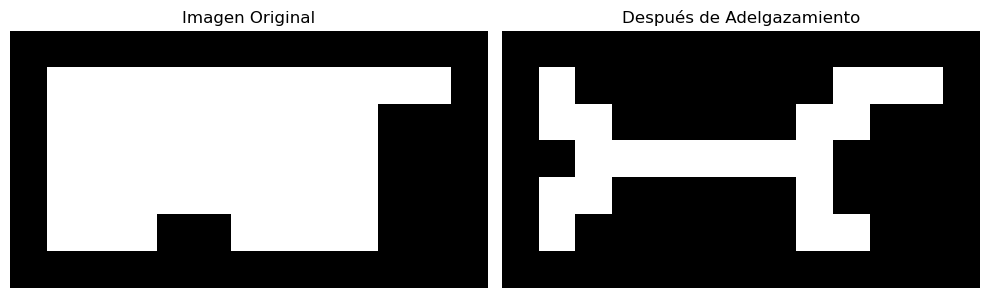

In [38]:
# ---------------------------
# Adelgazamiento morfológico
# ---------------------------
imagen_binaria = imagen.copy()
iteracion = 0

while True:
    cambio = False
    for i, (B1, B2) in enumerate(estructurantes):
        hitmiss = binary_hit_or_miss(imagen_binaria, structure1=B1, structure2=B2)
        if np.any(hitmiss):
            imagen_binaria = imagen_binaria & (~hitmiss)
            cambio = True
#            print(f'→ Aplicado B{i+1}: {np.sum(hitmiss)} píxeles removidos\n')

    iteracion += 1
#    print(f"Iteración {iteracion} completada\n{'='*40}")

    if not cambio or iteracion > 20:
        break


# ---------------------------
# Mostrar resultado
# ---------------------------
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(imagen_binaria, cmap='gray')
plt.title('Después de Adelgazamiento')
plt.axis('off')

plt.tight_layout()
plt.show()

In [39]:
# Crear una imagen binaria negra
imagen = np.zeros((100, 100), dtype=np.uint8)

# Dibujar la letra 'A' en blanco (centrada y más ancha)
cv2.putText(imagen, 'A', (15, 80), cv2.FONT_HERSHEY_SIMPLEX, 3, 255, 5, cv2.LINE_8)

A = (imagen == 255)

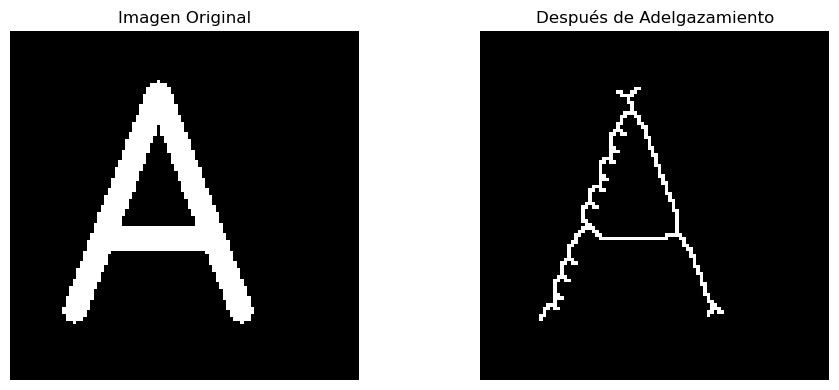

In [40]:
# ---------------------------
# Adelgazamiento morfológico
# ---------------------------
imagen_binaria = imagen.copy()
iteracion = 0

while True:
    cambio = False
    for i, (B1, B2) in enumerate(estructurantes):
        hitmiss = binary_hit_or_miss(imagen_binaria, structure1=B1, structure2=B2)
        if np.any(hitmiss):
            imagen_binaria = imagen_binaria & (~hitmiss)
            cambio = True
#            print(f'→ Aplicado B{i+1}: {np.sum(hitmiss)} píxeles removidos\n')

    iteracion += 1
#    print(f"Iteración {iteracion} completada\n{'='*40}")

    if not cambio or iteracion > 20:
        break


# ---------------------------
# Mostrar resultado
# ---------------------------
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(imagen_binaria, cmap='gray')
plt.title('Después de Adelgazamiento')
plt.axis('off')

plt.tight_layout()
#plt.savefig('fig/Latex/adelgazamiento.png', bbox_inches='tight', dpi=300)
plt.show()

---
## **Morfología Matemática en Escala de Grises**

### Erosión

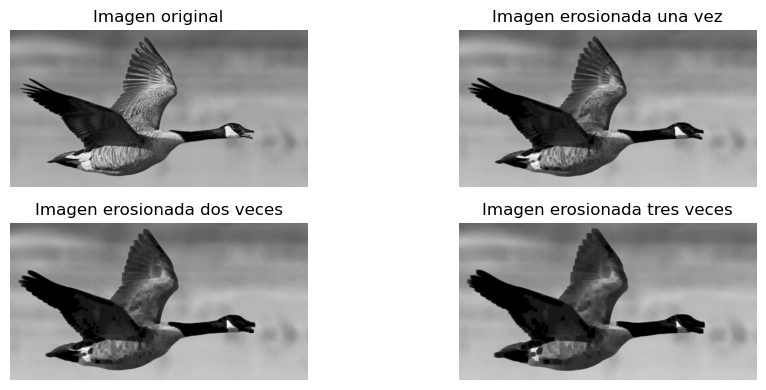

In [41]:
# Cargar la imagen en escala de grises
imagen = cv2.imread('./fig/Notebook/Ganso.png', cv2.IMREAD_GRAYSCALE)


# Crear un elemento estructurante (por ejemplo, cuadrado 3x3)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

# Aplicar erosión
imagen_erosionada = cv2.erode(imagen, kernel, iterations=1)
imagen_erosionada1 = cv2.erode(imagen_erosionada, kernel, iterations=1)
imagen_erosionada2 = cv2.erode(imagen_erosionada1, kernel, iterations=1)

# Visualizar el resultado
plt.figure(figsize=(10, 4))

plt.subplot(2, 2, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen original')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(imagen_erosionada, cmap='gray')
plt.title('Imagen erosionada una vez')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(imagen_erosionada1, cmap='gray')
plt.title('Imagen erosionada dos veces')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(imagen_erosionada2, cmap='gray')
plt.title('Imagen erosionada tres veces')
plt.axis('off')


plt.tight_layout()
#plt.savefig('fig/Latex/erosion_gris.png', bbox_inches='tight', dpi=300)
plt.show()


### Dilatación

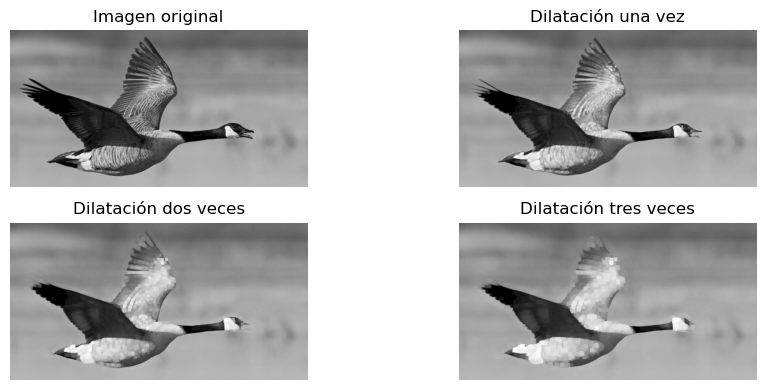

In [42]:
# 3. Aplicar dilataciones sucesivas
imagen_dilatada = cv2.dilate(imagen, kernel, iterations=1)
imagen_dilatada1 = cv2.dilate(imagen_dilatada, kernel, iterations=1)
imagen_dilatada2 = cv2.dilate(imagen_dilatada1, kernel, iterations=1)

# 4. Visualizar los resultados
plt.figure(figsize=(10, 4))

plt.subplot(2, 2, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen original')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(imagen_dilatada, cmap='gray')
plt.title('Dilatación una vez')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(imagen_dilatada1, cmap='gray')
plt.title('Dilatación dos veces')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(imagen_dilatada2, cmap='gray')
plt.title('Dilatación tres veces')
plt.axis('off')

plt.tight_layout()
#plt.savefig('fig/Latex/dilatacion_gris.png', bbox_inches='tight', dpi=300)
plt.show()

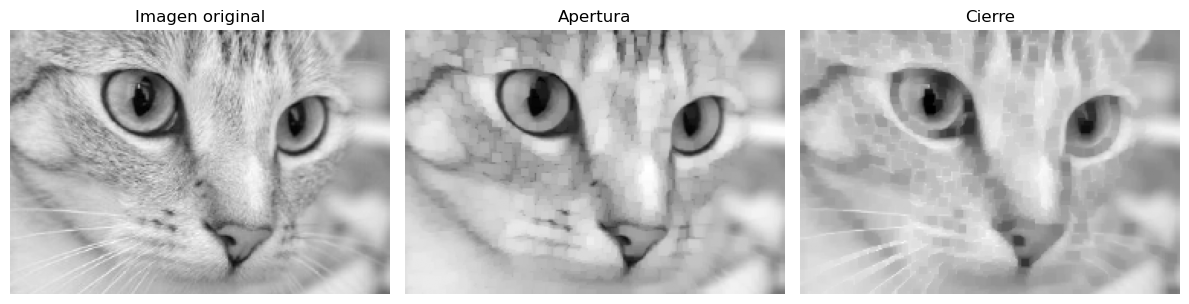

In [43]:
# Cargar la imagen en escala de grises
imagen = cv2.imread('./fig/Notebook/Gato.png', cv2.IMREAD_GRAYSCALE)

# 3. Aplicar apertura (erosión seguida de dilatación)
imagen_apertura = cv2.morphologyEx(imagen, cv2.MORPH_OPEN, kernel)

# 4. Aplicar cierre (dilatación seguida de erosión)
imagen_cierre = cv2.morphologyEx(imagen, cv2.MORPH_CLOSE, kernel)

# 5. Visualizar los resultados
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(imagen_apertura, cmap='gray')
plt.title('Apertura')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(imagen_cierre, cmap='gray')
plt.title('Cierre')
plt.axis('off')

plt.tight_layout()
#plt.savefig('fig/Latex/apertura_cierre_gris.png', bbox_inches='tight', dpi=300)
plt.show()

### Suavizado

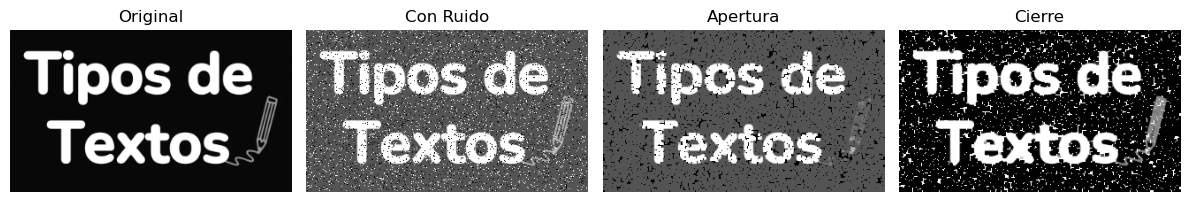

In [44]:
# Cargar imagen en escala de grises
imagen = cv2.imread('./fig/Notebook/Texto.png', cv2.IMREAD_GRAYSCALE)

# Verificar si la imagen fue cargada correctamente
if imagen is None:
    raise ValueError("No se pudo cargar la imagen. Verifica la ruta.")

# Agregar ruido sal y pimienta
def agregar_ruido_sal_pimienta(img, cantidad=0.05):
    salida = img.copy()
    num_pixels = int(cantidad * img.size)

    # Sal (blanco)
    coords_sal = [np.random.randint(0, i - 1, num_pixels) for i in img.shape]
    salida[coords_sal[0], coords_sal[1]] = 255

    # Pimienta (negro)
    coords_pimienta = [np.random.randint(0, i - 1, num_pixels) for i in img.shape]
    salida[coords_pimienta[0], coords_pimienta[1]] = 0

    return salida

imagen_con_ruido = agregar_ruido_sal_pimienta(imagen, cantidad=0.05)

# rear elemento estructurante
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

# Aplicar apertura y cierre morfológico
imagen_apertura = cv2.morphologyEx(imagen_con_ruido, cv2.MORPH_OPEN, kernel)
imagen_cierre = cv2.morphologyEx(imagen_con_ruido, cv2.MORPH_CLOSE, kernel)

# Visualizar resultados
imagenes = [imagen, imagen_con_ruido, imagen_apertura, imagen_cierre]
titulos = ['Original', 'Con Ruido', 'Apertura', 'Cierre']

plt.figure(figsize=(12, 4))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(imagenes[i], cmap='gray')
    plt.title(titulos[i])
    plt.axis('off')

plt.tight_layout()
#plt.savefig('fig/Latex/Elimin_Ruido_gris.png', bbox_inches='tight', dpi=300)
plt.show()


### Gradiente morfológico

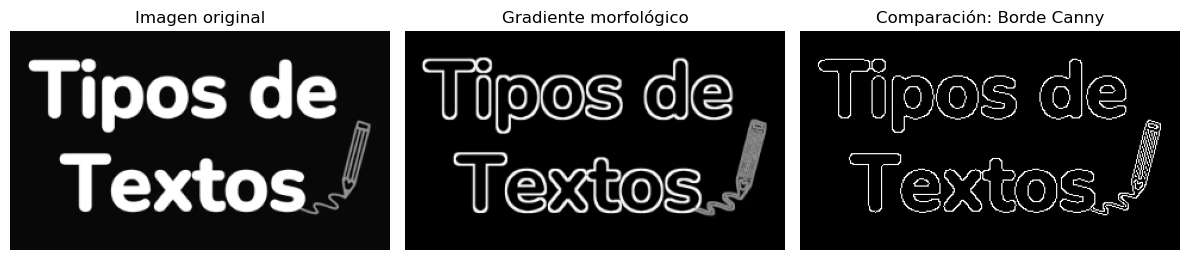

In [45]:
# Cargar la imagen en niveles de gris
imagen = cv2.imread('./fig/Notebook/Texto.png', cv2.IMREAD_GRAYSCALE)

# Definir el elemento estructurante
kernel = np.ones((3, 3), np.uint8)

# Aplicar dilatación y erosión
dilatada = cv2.dilate(imagen, kernel, iterations=1)
erosionada = cv2.erode(imagen, kernel, iterations=1)

# Gradiente morfológico: dilatación - erosión
gradiente = cv2.subtract(dilatada, erosionada)

# Visualización
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap='gray')
plt.title('Imagen original')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(gradiente, cmap='gray')
plt.title('Gradiente morfológico')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.Canny(imagen, 100, 200), cmap='gray')
plt.title('Comparación: Borde Canny')
plt.axis('off')

plt.tight_layout()
#plt.savefig('fig/Latex/gradiente_morfologico_gris.png', bbox_inches='tight', dpi=300)
plt.show()